# Исследование рынка недвижимости РФ

## <a class="anchor" id="1"> Навигация:
[Задание](#2)<br>
[Описание данных](#3)<br>
[1. Знакомство с данными](#4)<br>
[Вывод](#5)<br>
[2. Добавление информации из другого датасета](#6)<br>
[Выводы](#7)<br>
[Исследование и устранение аномалий](#8)<br>
[Выводы](#9)<br>
[3. Заполнение пропусков](#10)<br>
[Выводы](#11)<br>
[4. Исследование рынка недвижимости в РФ за представленный период](#12)<br>
[Выводы по коду региона](#13)<br>
[Выводы по типу рынка](#14)<br>
[Выводы по количеству комнат](#15)<br>
[Выводы по дате](#16)<br>
[Выводы по году](#17)<br>
[Выводы по типу дома](#18)<br>
[Выводы по номеру этажа](#19)<br>
[Выводы по количеству этажей](#20)<br>
[Выводы по типу этажа ](#21)<br>
[5. Исследование периода для выгодной покупки/продажи недвижимости](#22)<br>
[Выводы](#23)<br>
[6. Исследование от каких признаков зависит стоимость объекта недвижимости. Поиск скрытых закономерностей](#24)<br>
[Выводы](#25)<br>
[7. Выдвижение собственной гипотезы и ее проверка](#26)<br>
[Выводы](#27)<br>
[8. Создание модели прогноза объекта недвижимости](#28)<br>
[Выводы](#29)<br>
[Итоговые выводы](#30)<br>

## <a class="anchor" id="2"> Задание


1. Познакомьтесь с данными.
2. Добавьте информацию из датасета region.csv.
3. Восстановите пропуски в столбце kitchen_area. 
4. Исследуйте рынок недвижимости в РФ за представленный период. Величина исследования - цена за м2. Обработайте аномалии.
5. Когда выгодно покупать/продавать объект недвижимости? 
6. Определите от каких признаков зависит стоимость объекта недвижимости. Найдите скрытые закономерности.
7. Выдвинете и проверьте собственную гипотезу статистическими методами.
8. Создайте модель прогноза цены объекта недвижимости.

[Вернуться к Навигации](#1)

## <a class="anchor" id="3"> Описание данных

[Вернуться к Навигации](#1)

## <a class="anchor" id="4"> 1. Знакомство с данными

1. Познакомьтесь с данными.

In [4]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats as st
from datetime import datetime 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import  mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [5]:
#импортируем датасет
data = pd.read_csv('../data/realty_18_21.csv')
data.head(1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1


In [6]:
#выводим основную информацию
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5477006 entries, 0 to 5477005
Data columns (total 10 columns):
 #   Column         Dtype  
---  ------         -----  
 0   price          int64  
 1   date           object 
 2   region         int64  
 3   building_type  int64  
 4   level          int64  
 5   levels         int64  
 6   rooms          int64  
 7   area           float64
 8   kitchen_area   float64
 9   object_type    int64  
dtypes: float64(2), int64(7), object(1)
memory usage: 417.9+ MB


In [7]:
#смотрим количество строк и столбцов
data.shape

(5477006, 10)

[Вернуться к Навигации](#1)

## <a class="anchor" id="5"> Вывод

##### Датасет о недвижимости имеет 5 477 006 строк и 10 столбцов. Из типов данных нужно перевести дату в правильный формат. 

[Вернуться к Навигации](#1)

## <a class="anchor" id="6"> 2. Добавление информации из другого датасета

2. Добавьте информацию из датасета region.csv.

In [8]:
#импортируем датасет
region = pd.read_csv('../data/region.csv')
region.head(1)

,code,reg_name
0,2661,Санкт-Петербург


In [9]:
#выводим основную информацию
region.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   code      83 non-null     object
 1   reg_name  83 non-null     object
dtypes: object(2)
memory usage: 1.4+ KB


In [10]:
#смотрим количество строк и столбцов
region.shape

(83, 2)

In [11]:
#для удобства сделаем названия столбцов одинаковыми
data = data.rename(columns={'region': 'code'})
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1


In [12]:
#смотрим сколько уникальных значений в каждом датасете
data['code'].nunique()

84

In [13]:
#смотрим сколько уникальных значений в каждом датасете
region['code'].nunique()

83

Не совпадает, значит есть ошибка в данных

In [14]:
#не с первого раза находим в чем дело 
region['code'].unique()

array(['2661', '3446', '3', '81', '2843', '2871', '3230', '3106', '2922',
       '2900', '2722', '6171', '4417', '5282', '5368', '5520', '6817',
       '9579', '2604', '1010', '7793', '13919', '2860', '3019', '4982',
       '9648', '5241', '3870', '3991', '2359', '9654', '2072', '8090',
       '4007', '11171', '10160', '7873, 6937', '2594', '8509', '11416',
       '11991', '5178', '13913', '6309', '5952', '6543', '2880', '5993',
       '2484', '4240', '5789', '14880', '1491', '2885', '5794', '2528',
       '4374', '4695', '2328', '5143', '2806', '14368', '5736', '7121',
       '4086', '821', '10582', '7896', '8640', '5703', '10201', '4249',
       '3153', '4189', '2814', '13098', '8894', '7929', '16705', '69',
       '4963', '1901', '61888'], dtype=object)

Коды 7873 и 6937 слиплись в один '7873, 6937'. Оба кода принадлежат Республике Крым

In [15]:
region.iloc[36, 0] = 7873 #добавим соответствующую строку
new_row = pd.DataFrame({'code': [6937], 'reg_name': ['Республика Крым']}) #создадим датафрейм для отельной строки
region = pd.concat([region, new_row], ignore_index=True) #добавим эту строку к остальному датафрейму

In [16]:
#проверяем
region[region['reg_name'] == 'Республика Крым']

,code,reg_name
36,7873,Республика Крым
83,6937,Республика Крым


In [17]:
#переведем коды регионов в нужный формат
region['code'] = region['code'].astype('int')

In [18]:
#добавим столбец с названием региона для дальнейшего анализа
data = pd.merge(data, region, on='code', how='left')
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург


[Вернуться к Навигации](#1)

## <a class="anchor" id="7"> Вывод

##### Датасет о регионах имеет 83 строки и 2 столбца. Пришлось понять, почему количество уникальных кодов отличается и вручную исправить данные. Еще из типов данных нужно было перевести код региона в правильный формат. С присоединением к датасету о недвижимости проблем не возникло

[Вернуться к Навигации](#1)

## <a class="anchor" id="8"> Исследование и устранение аномалий

Обрабатывать пропуски неправильно на неочищенных данных, поэтому займемся этим сейчас

In [19]:
#переведем дату в нужный формат
data['date'] = pd.to_datetime(data['date'], format = '%Y-%m-%d')

In [20]:
#ищем аномалии
data[data['level'] > data['levels']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name
26283,1850000,2018-09-12,3870,3,17,13,1,37.0,10.0,1,Красноярский край
35903,1100000,2018-09-13,9654,3,4,1,1,30.0,8.0,1,Новосибирская область
117969,700000,2018-09-22,2722,3,2,1,2,40.0,11.0,1,Республика Башкортостан
148751,3200000,2018-09-27,11171,2,4,3,1,31.0,10.0,1,Республика Саха (Якутия)
164863,1050000,2018-09-28,2843,4,2,1,2,54.0,10.0,1,Краснодарский край


In [21]:
#подсчитываем сколько таких строк
data['level'][data['level'] > data['levels']].count()

1072

Хорошо подумав, было принято решение удалить эти строки, так как правильный номер этажа мы точно не узнаем

In [22]:

#удаляем их
data = data[data['level'] <= data['levels']]
data.shape #проверяем

(5475934, 11)

In [23]:
#ищем дальше аномалии
data['building_type'].unique()

array([1, 3, 4, 2, 5, 0])

In [24]:
#ищем дальше аномалии
data['level'].unique()

array([ 8,  5, 12, 13,  4,  1,  2,  9, 10, 25,  7,  6, 16, 17, 14, 11,  3,
       18, 15, 23, 21, 20, 22, 19, 28, 24, 26, 32, 30, 27, 31, 29, 34, 33,
       35, 37, 36, 39, 38])

In [25]:
#ищем дальше аномалии
data['levels'].unique()

array([10, 24,  9, 16, 14,  5, 25, 15, 17,  8,  2,  3, 18,  4, 22, 12, 20,
        7, 19,  6, 23, 27,  1, 21, 11, 28, 13, 36, 26, 33, 34, 30, 29, 35,
       32, 31, 37, 38, 39])

In [26]:
#ищем дальше аномалии
data['rooms'].unique()

array([ 3,  2,  1,  4, -1,  5,  7,  6,  8,  9, -2, 10])

Опа, нашли, что есть какое-то странное количество комнат... Может это дважды студия xD

In [27]:
#подсчитываем сколько таких строк
data['rooms'][data['rooms'] == -2].count()

343

Так как таких строк немного опять же удалим их

In [28]:
#удаляем их
data = data[data['rooms'] != -2]
data.shape #проверяем

(5475591, 11)

In [29]:
#ищем дальше аномалии
data['object_type'].unique()

array([ 1, 11])

In [30]:
#ищем аномалии
data[data['kitchen_area'] >= data['area']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name
502,4599000,2018-09-08,9654,3,6,10,2,5.60,7.70,1,Новосибирская область
673,1350000,2018-09-08,9654,1,5,10,1,13.78,48.02,11,Новосибирская область
3055,950000,2018-09-08,9654,3,2,9,-1,22.00,22.00,1,Новосибирская область
4111,1200000,2018-09-08,2359,3,3,9,-1,23.00,23.00,11,Республика Хакасия
4500,1570000,2018-09-08,1010,3,4,5,1,32.00,65.00,1,Удмуртская Республика


Опять же ошибка в данных, кто-то явно любит место, чтобы готовить

In [31]:
#подсчитываем сколько таких строк
data[data['kitchen_area'] >= data['area']]['area'].count()

4207

Подсчитать подсчитали, но удалять пока не будем. Дальше расскажем в чем дело

In [32]:
#проверим пропуски
data.isna().sum()

price                 0
date                  0
code                  0
building_type         0
level                 0
levels                0
rooms                 0
area                  0
kitchen_area     253657
object_type           0
reg_name              0
dtype: int64

Ой, неприятно получилось. Пропуски как раз там, где мы не сделали прошлый шаг

In [33]:
#удаляем строки с аномалиями
data = data[(data['kitchen_area'].isna()) | (data['kitchen_area'] < data['area'])]
data.shape

(5471384, 11)

In [34]:
data[data.duplicated()].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name
466,1300000,2018-09-08,9654,1,5,10,1,41.36,10.88,11,Новосибирская область
516,906660,2018-09-08,9654,1,8,10,1,33.58,5.00,11,Новосибирская область
589,1050000,2018-09-08,9654,1,3,10,1,33.58,5.00,1,Новосибирская область
604,2250000,2018-09-08,9654,1,10,10,2,64.00,12.00,1,Новосибирская область
627,940000,2018-09-08,9654,1,4,10,1,33.58,5.00,11,Новосибирская область


Пропуски есть как для первичного рынка, как и для вторичного. Для первичного рынка это возможно, так как в день выставляется множество однотипных объявлений в новом доме

In [35]:
#посмотрим  конкретно вторичный рынок
data[data.duplicated()][data['object_type'] == 1].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name
589,1050000,2018-09-08,9654,1,3,10,1,33.58,5.0,1,Новосибирская область
604,2250000,2018-09-08,9654,1,10,10,2,64.00,12.0,1,Новосибирская область
714,2310000,2018-09-08,9654,1,1,10,3,59.02,8.5,1,Новосибирская область
787,1750000,2018-09-08,9654,1,9,10,1,58.03,17.0,1,Новосибирская область
961,5789000,2018-09-08,9654,3,3,10,3,99.90,12.6,1,Новосибирская область


In [36]:
#подсчитаем число дубликатов
data[data.duplicated()][data['object_type'] == 1]['object_type'].count()

91426

In [37]:
#удалим эти дубликаты
data = data[~((data.duplicated()) & (data['object_type'] == 1))]
data.shape #проверка

(5379958, 11)

Теперь разберемся с аномальными ценами и площадями квартир, чтобы избежать ситуации на картинке

<div style="text-align: center;">
    <img src="https://n1s1.hsmedia.ru/8e/b3/72/8eb372c655840f6d7b2aa96d47d3c02f/486x600_1_6351e8436cf866c5fe3e73f5a199ec88@1500x1850_0xac120004_18686076501687870461.jpeg.webp" alt="Описание изображения" style="width: 300px;"/>
</div>

In [38]:
#смотри, что не так
data['price'].describe()

count    5.379958e+06
mean     4.438628e+06
std      2.140699e+07
min     -2.144967e+09
25%      1.950000e+06
50%      3.000000e+06
75%      4.855000e+06
max      2.147484e+09
Name: price, dtype: float64

In [39]:
#смотрим, что не так
data['area'].describe()

count    5.379958e+06
mean     5.394917e+01
std      3.339634e+01
min      2.200000e-01
25%      3.800000e+01
50%      4.802000e+01
75%      6.313000e+01
max      7.856000e+03
Name: area, dtype: float64

In [40]:
#введем такие хитрые столбцы
data['price_for_1m2'] = round(data['price'] / data['area'], 2)
data['area_for_room'] = np.where(data['kitchen_area'].isna(), round(data['area'] / abs(data['rooms']), 2), round((data['area'] - data['kitchen_area']) / abs(data['rooms']), 2))
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93


Да, вводить метрику площадь на комнату не совсем правильно, так как она не учитывает санузлы, коридор и балкон. Но она введена для борьбы с экстремально странными квартирами. Как вам квартира 2м2, где 5 комнат?! Также неправильно делать это, так как у нас есть пропуски, но минимальное значение общей площади 0.2 м2, это вообще как?! 

In [41]:
#вручную ищем адекватное значение перцентиля
area_for_room_ejection_l = np.percentile(data['area_for_room'], 0.15)
area_for_room_ejection_l

5.87

In [42]:
#удостоверяемся, что делаем все правильно
data[data['area_for_room'] < area_for_room_ejection_l].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
900,1451892000,2018-09-08,9654,1,9,10,3,59.02,45.5,11,Новосибирская область,24600000.00,4.51
2964,650000,2018-09-08,3230,1,8,9,5,17.20,NaN,1,Ростовская область,37790.70,3.44
5224,1451892000,2018-09-09,9654,1,9,10,3,59.02,45.5,11,Новосибирская область,24600000.00,4.51
6556,2280000,2018-09-09,5368,1,2,5,2,31.00,20.0,1,Иркутская область,73548.39,5.50
7502,3400000,2018-09-09,81,3,4,5,3,57.90,41.1,1,Московская область,58721.93,5.60


Как и предполагалось, что допущения выше стоят того, чтобы удалить эти странные квартиры. Какая 5-ти комнатная квартира 17.2 м2...

In [43]:
#проделываем то же самое, но уже для верхней границы
area_for_room_ejection_h = np.percentile(data['area_for_room'], 99.99)
area_for_room_ejection_h

347.30085999984294

In [44]:
#удостоверяемся, что делаем все правильно
data[data['area_for_room'] > area_for_room_ejection_h].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
6696,1550000,2018-09-09,2860,1,6,10,1,403.0,NaN,1,Кемеровская область,3846.15,403.0
32252,2890000,2018-09-13,2843,2,3,10,2,753.0,24.0,1,Краснодарский край,3837.98,364.5
55998,1750000,2018-09-16,5368,1,6,9,1,391.0,12.0,11,Иркутская область,4475.70,379.0
58950,2890000,2018-09-17,2843,2,3,10,2,753.0,24.0,1,Краснодарский край,3837.98,364.5
63159,650000,2018-09-17,9648,3,5,5,1,380.0,10.0,1,Кабардино-Балкарская Республика,1710.53,370.0


Видим, что это выбросы даже больше для цены на квадратный метр, но и значение перцентиля 99.99. Вот бы и мне до 4 500 рублей за 1 м2

In [45]:
#удаляем эти строки 
data = data[(data['area_for_room'] > area_for_room_ejection_l) & (data['area_for_room'] < area_for_room_ejection_h)]
data.shape #проверяем

(5371349, 13)

In [46]:
#посмотрим, что изменилось
data['area'].describe()

count    5.371349e+06
mean     5.386605e+01
std      2.587986e+01
min      6.200000e+00
25%      3.810000e+01
50%      4.802000e+01
75%      6.313000e+01
max      1.500000e+03
Name: area, dtype: float64

Минимальная площадь уже 6.2 м2, для каких-то апартаментов может и нормально 

In [47]:
#построим, что изменилось
data['price'].describe()

count    5.371349e+06
mean     4.437823e+06
std      2.134061e+07
min     -2.144967e+09
25%      1.950000e+06
50%      3.000000e+06
75%      4.860000e+06
max      2.147484e+09
Name: price, dtype: float64

Время разобраться с отрицательной ценой

In [48]:
#вручную ищем адекватное значение перцентиля
price_for_1m2_ejection_l = np.percentile(data['price_for_1m2'], 0.15)
price_for_1m2_ejection_l

5882.35

In [49]:
#удостоверяемся, что делаем все правильно
data[data['price_for_1m2'] < price_for_1m2_ejection_l].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
2321,800,2018-09-08,6171,1,3,5,1,32.0,6.00,1,Свердловская область,25.00,26.00
3114,200000,2018-09-08,4417,3,2,2,2,46.5,6.10,1,Республика Коми,4301.08,20.20
3484,2826000,2018-09-08,3106,3,1,10,3,942.0,11.00,1,Самарская область,3000.00,310.33
3576,3384711,2018-09-08,6171,0,2,16,2,590.7,11.84,11,Свердловская область,5730.00,289.43
3633,150000,2018-09-08,4417,1,5,5,3,72.0,9.00,1,Республика Коми,2083.33,21.00


Аж захотелось квартиру за 800 рублей

In [50]:
#проделываем то же самое, но уже для верхней границы
price_for_1m2_ejection_h = np.percentile(data['price_for_1m2'], 99.9)
price_for_1m2_ejection_h

613421.8399600387

In [51]:
#удостоверяемся, что делаем все правильно
data[data['price_for_1m2'] > price_for_1m2_ejection_h].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
908,1003425000,2018-09-08,9654,1,9,10,1,39.35,4.39,11,Новосибирская область,25500000.00,34.96
3401,118500000,2018-09-08,3,2,6,10,4,180.00,25.00,1,Москва,658333.33,38.75
4787,175500000,2018-09-08,3,2,17,17,5,237.00,14.00,1,Москва,740506.33,44.60
5215,1003425000,2018-09-09,9654,1,9,10,1,39.35,4.39,11,Новосибирская область,25500000.00,34.96
9044,63000000,2018-09-09,3,2,23,34,3,99.00,26.00,1,Москва,636363.64,24.33


Что ж там за 1-комнатная квартира 39.35 м2 за 1 003 425 000 рублей. Может я завидую...?

In [52]:
#удаляем эти строки 
data = data[(data['price_for_1m2'] > price_for_1m2_ejection_l) & ((data['price_for_1m2'] < price_for_1m2_ejection_h))]
data.shape

(5357891, 13)

In [53]:
#смотрим, что изменилось
data['price'].describe()

count    5.357891e+06
mean     4.318396e+06
std      5.232010e+06
min      7.760000e+04
25%      1.950000e+06
50%      3.000000e+06
75%      4.850000e+06
max      5.200003e+08
Name: price, dtype: float64

In [54]:
#тоже проверим на всякий случай
data[data['price'] == data['price'].describe()['min']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
5275960,77600,2021-04-03,2922,1,3,5,1,10.0,2.0,1,Республика Татарстан,7760.0,8.0


Ура, теперь нет отрицательных цен! А вот квартира за 77 600 рублей в ценах 2021 года где-нибудь в глуши в полне может быть

In [55]:
#тоже проверим на всякий случай
data[data['price'] == data['price'].describe()['max']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
2853324,520000345,2019-11-08,2661,0,1,3,5,1211.0,21.6,1,Санкт-Петербург,429397.48,237.88
2875101,520000345,2019-11-13,2661,0,1,3,5,1211.0,21.6,1,Санкт-Петербург,429397.48,237.88
3100050,520000345,2019-12-29,2661,0,1,3,5,1211.0,21.6,1,Санкт-Петербург,429397.48,237.88
3318136,520000345,2020-02-22,2661,0,1,3,5,1211.0,21.6,1,Санкт-Петербург,429397.48,237.88
3591384,520000345,2020-04-11,2661,0,1,3,5,1211.0,21.6,1,Санкт-Петербург,429397.48,237.88


В принципе, выглядит более менее адекватно. До удаления строк максимальная цена была больше 2х миллиардов 

In [56]:
#смотрим, что изменилось
data['area'].describe()

count    5.357891e+06
mean     5.367319e+01
std      2.444170e+01
min      7.900000e+00
25%      3.810000e+01
50%      4.802000e+01
75%      6.313000e+01
max      1.385000e+03
Name: area, dtype: float64

In [57]:
#проверим результат
data[data['area'] == data['area'].describe()['min']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
1396996,733000,2019-03-19,3991,3,5,5,1,7.9,2.0,1,Тюменская область,92784.81,5.9
1614616,733000,2019-04-15,3991,3,5,5,1,7.9,2.0,1,Тюменская область,92784.81,5.9
1987294,733000,2019-06-13,3991,3,5,5,1,7.9,2.0,1,Тюменская область,92784.81,5.9
2758566,650000,2019-10-18,3991,3,5,5,1,7.9,1.5,1,Тюменская область,82278.48,6.4
2818630,630000,2019-10-31,3991,3,5,5,1,7.9,2.0,1,Тюменская область,79746.84,5.9


В принципе, выглядит более менее адекватно. До удаления строк минимальная площадь была 0.2 м2 

In [58]:
#проверим результат
data[data['area'] == data['area'].describe()['max']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
3741431,9974000,2020-05-15,2843,3,20,21,4,1385.0,28.0,1,Краснодарский край,7201.44,339.25


Что-то не нравится цена за 1м2. Удалим от греха подальше 

In [59]:
#удаляем эту строку
data = data[~(data['area'] == data['area'].describe()['max'])]
data.shape

(5357890, 13)

In [60]:
#проверим результат
data[data['area'] == data['area'].describe()['max']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
1844696,17500000,2019-05-22,2843,2,16,25,4,1300.0,220.0,1,Краснодарский край,13461.54,270.0


Теперь стало явно лучше. Напоследок чуть-чуть приведем в порядок размер кухонь

In [61]:
#смотрим, что мы имеем
data['kitchen_area'].describe()

count    5.105537e+06
mean     1.059202e+01
std      5.451672e+00
min      1.000000e-02
25%      7.000000e+00
50%      9.700000e+00
75%      1.267000e+01
max      2.500000e+02
Name: kitchen_area, dtype: float64

Минимальный размер кухни 0.01 м2, с этим нужно что-то сделать

In [62]:
#вручную ищем адекватное значение перцентиля
kitchen_area_ejection_l = np.percentile(data[~data['kitchen_area'].isna()]['kitchen_area'], 0.325)
kitchen_area_ejection_l

1.4

In [63]:
#вручную ищем адекватное значение перцентиля
kitchen_area_ejection_h = np.percentile(data[~data['kitchen_area'].isna()]['kitchen_area'], 99.99)
kitchen_area_ejection_h

82.0

In [64]:
#удаляем эти строки 
data = data[(data['kitchen_area'].isna()) | ((data['kitchen_area'] > kitchen_area_ejection_l) & (data['kitchen_area'] < kitchen_area_ejection_h))]
data.shape

(5340765, 13)

In [65]:
#смотрим, что изменилось
data['kitchen_area'].describe()

count    5.088412e+06
mean     1.061444e+01
std      5.352951e+00
min      1.420000e+00
25%      7.000000e+00
50%      9.800000e+00
75%      1.270000e+01
max      8.190000e+01
Name: kitchen_area, dtype: float64

In [66]:
#проверим результат
data[data['kitchen_area'] == data['kitchen_area'].describe()['min']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
2965976,1920000,2019-12-01,3991,0,10,17,-1,31.72,1.42,11,Тюменская область,60529.63,30.3


Так как мы понятия не имеем, как считается площадь кухни в студиях, то сделаем вид, что это нормально. Хотя бы это лучше, чем до удаления выбросов

In [67]:
#проверим результат
data[data['kitchen_area'] == data['kitchen_area'].describe()['max']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
2864360,65934000,2019-11-11,2661,0,10,10,3,232.4,81.9,1,Санкт-Петербург,283709.12,50.17
3377853,65934000,2020-03-01,2661,0,10,10,3,232.4,81.9,1,Санкт-Петербург,283709.12,50.17
4213977,65934000,2020-08-03,2661,2,10,11,3,232.4,81.9,11,Санкт-Петербург,283709.12,50.17
4524494,65930000,2020-10-07,2661,2,10,11,3,232.4,81.9,1,Санкт-Петербург,283691.91,50.17
4922731,65930000,2021-01-06,2661,2,10,11,4,232.4,81.9,1,Санкт-Петербург,283691.91,37.62


К максимальному размеру кухни вопросов вообще нет

[Вернуться к Навигации](#1)

## <a class="anchor" id="9"> Вывод

##### Были удалены такие аномалии, как превышение номера этажа общего количества этажей, превышение размера кухни общей площади, неизвестное обозначение '-2' для количества комнат, удалены дубликаты для вторичного рынка. Также с помощью внедренных метрик - цена за квадратный метр и площадь для 1 комнаты мы сумели избавиться от отрицательных и сверх высоких цен (такое может быть, но это явно выброс) и от экстремально маленькой общей площади. Отдельно убрали экстремально маленькие кухни и чуть экстремально больших. Стоит отметить, что от исходного датасета мы удалили меньше 2,5% строк, что является допустимым для такого большого массива данных

[Вернуться к Навигации](#1)

## <a class="anchor" id="10"> 3. Заполнение пропусков

3. Восстановите пропуски в столбце kitchen_area. 

Было решено, создать модель, обучить ее на очищенных от аномалий данных и заполнить пропуски!

In [68]:
#  кодировщик LabelEncoder() записываем в переменную encoder
encoder = LabelEncoder()
# трансформируем строковые значения столбца 'brand'  в числа с помошью fit_transform
data['code'] = encoder.fit_transform(data['code'])
data['code'].unique()

array([14,  2, 20, 18,  0, 26, 24, 23, 15, 54, 28, 38, 45, 46, 29, 47, 57,
       68, 13,  4, 69, 60, 79, 19, 25, 41, 44, 30, 31,  9, 70,  7, 64, 32,
       74, 71, 61, 12, 65, 75, 76, 21, 43, 78, 55, 52, 56,  8, 53, 10, 77,
       35, 50, 81, 72,  5, 22, 51, 11, 37, 39, 42, 58, 16, 80, 49, 59, 33,
        3, 73, 62, 66, 48, 67, 36, 27, 34, 17, 63, 82,  1, 40,  6, 83])

In [69]:
data[~data['kitchen_area'].isnull()][['price', 'date', 'code', 'building_type', 'level', 'levels', 'rooms',
       'area', 'kitchen_area', 'object_type']].corr(method='spearman')['kitchen_area']

price            0.450258
date             0.042703
code            -0.126549
building_type    0.022873
level            0.252097
levels           0.381018
rooms            0.215142
area             0.520496
kitchen_area     1.000000
object_type      0.237769
Name: kitchen_area, dtype: float64

In [70]:
#создадим датафрейм без пропусков
df_kitchen_area_not_nan = data[~data['kitchen_area'].isna()]

In [71]:
#определимся с переменными
y = df_kitchen_area_not_nan['kitchen_area']
x = df_kitchen_area_not_nan[['price', 'code', 'building_type', 'level', 'levels', 'rooms', 'area']]

In [72]:
#посчитаем количество строк, которые нужно заполнить
n = data[data['kitchen_area'].isna()].shape[0]
n

252353

In [73]:
#разделим данных на обучающую и тестовую выборки
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=n, random_state=0)

In [74]:
#создадим модель случайный лес
model = RandomForestRegressor(n_estimators=100, random_state=0)

#обучим ее на наших данных
model.fit(x_train, y_train)

RandomForestRegressor(random_state=0)

In [75]:
#делаем прогноз
y_pred = model.predict(x_test)

In [76]:
#для интереса смотрим что получилось
y_pred

array([10.7426    , 10.527     ,  9.48062857, ..., 10.6095    ,
       15.40415   , 10.49866667])

In [ ]:
#посчитаем разные метрики, чтобы оценить качество нашей модели
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Среднеквадратическая ошибка (MSE):", mse)
print("Среднеквадратическая ошибка (RMSE):", rmse)
print("Средняя абсолютная ошибка (MAE):", mae)
print("Средняя абсолютная процентная ошибка (MAPE):", mape)
print("Коэффициент детерминации (R^2):", r2)


Среднеквадратическая ошибка (MSE): 9.455085061981613
Среднеквадратическая ошибка (RMSE): 3.074912203946905
Средняя абсолютная ошибка (MAE): 1.4990318777121787
Средняя абсолютная ошибка  (MAPE): 0.14283704167691988
Коэффициент детерминации (R^2): 0.6727912460466732


Модель имеет разумную точность, R² показывает, что значительная доля вариации объясняется. Как нам кажется, что заполняя пропуски через средние, выбирая несколько признаков менее точно, чем использовать модель

In [78]:
#заполним пропуски
data.loc[data['kitchen_area'].isna(), 'kitchen_area'] = y_pred

In [79]:
#округли площадь кухни до 2х знаков после запятой
data['kitchen_area'] = round(data['kitchen_area'], 2)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93


In [80]:
#посмотрим, что изменилось
data['kitchen_area'].describe()

count    5.340765e+06
mean     1.061785e+01
std      5.319771e+00
min      1.420000e+00
25%      7.000000e+00
50%      9.800000e+00
75%      1.270000e+01
max      8.190000e+01
Name: kitchen_area, dtype: float64

In [81]:
#проверим результат
data[data['kitchen_area'] == data['kitchen_area'].describe()['min']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
2965976,1920000,2019-12-01,31,0,10,17,-1,31.72,1.42,11,Тюменская область,60529.63,30.3


В принципе, для больших апартаментов или студий, где кстати непонятно, что считается кухней, такая площадь кухни возможна.

Теперь проверим, сколько приходится площади на одну комнату после заполнения пропусков

In [82]:
#проверим, нет ли аномалий
data['area_for_room'] = round((data['area'] - data['kitchen_area']) / abs(data['rooms']), 2)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93


In [83]:
#проверим, нет ли аномалий
data[data['kitchen_area'] >= data['area']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
17809,6500000,2018-09-10,0,1,7,9,2,39.0,41.53,1,Москва,166666.67,-1.27
17870,2180000,2018-09-10,24,1,2,10,1,30.0,30.94,1,Республика Татарстан,72666.67,-0.94
20312,545000,2018-09-11,28,3,2,5,1,20.0,21.60,1,Ростовская область,27250.00,-1.60
26618,800000,2018-09-12,71,1,1,2,1,39.4,49.16,1,Забайкальский край,20304.57,-9.76
40227,1350000,2018-09-13,24,1,1,10,-1,18.2,18.26,1,Республика Татарстан,74175.82,-0.06


Из-за того, что вариация площади кухонь только на 67,3% объясняется вариацией нашей модели, то, к сожалению, опять получилось, что в некоторых случаях площадь кухни больше общей площади 

In [84]:
#подсчитаем, сколько таких строк
data['kitchen_area'][data['kitchen_area'] >= data['area']].count()

632

In [85]:
#удалим эти строки
data = data[data['kitchen_area'] < data['area']]
data.shape

(5340133, 13)

In [86]:
#посмотрим, что изменилось
data['kitchen_area'].describe()

count    5.340133e+06
mean     1.061560e+01
std      5.314112e+00
min      1.420000e+00
25%      7.000000e+00
50%      9.800000e+00
75%      1.270000e+01
max      8.190000e+01
Name: kitchen_area, dtype: float64

In [87]:
#посмотрим, что изменилось
data['area_for_room'].describe()

count    5.340133e+06
mean     2.464525e+01
std      7.683415e+00
min      2.000000e-02
25%      1.967000e+01
50%      2.400000e+01
75%      2.800000e+01
max      3.473000e+02
Name: area_for_room, dtype: float64

In [88]:
#удостоверяемся, что делаем все правильно
data[data['area_for_room'] == data['area_for_room'].describe()['min']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
4953199,2400000,2021-01-23,0,1,2,19,-1,10.8,10.78,1,Москва,222222.22,0.02


Подчистим через перцентили такие случаи

In [89]:
#вручную ищем адекватное значение перцентиля
area_for_room_ejection_l = np.percentile(data['area_for_room'], 0.15)
area_for_room_ejection_l

7.77

In [90]:
#удостоверяемся, что делаем все правильно
data[data['area_for_room'] < area_for_room_ejection_l].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
172,2700000,2018-08-15,29,3,3,5,2,45.0,31.0,1,Ленинградская область,60000.00,7.00
2858,3000000,2018-09-08,32,2,6,10,1,51.0,45.0,1,Республика Дагестан,58823.53,6.00
3536,3350000,2018-09-08,2,1,2,9,3,64.0,41.0,1,Московская область,52343.75,7.67
3922,2850000,2018-09-08,54,1,1,5,2,45.0,30.0,1,Свердловская область,63333.33,7.50
4801,850000,2018-09-09,28,3,5,5,1,21.0,14.0,1,Ростовская область,40476.19,7.00


In [91]:
#удалим эти строки
data = data[data['area_for_room'] > area_for_room_ejection_l]
data.shape #проверка

(5332104, 13)

In [92]:
#посмотрим, что изменилось
data['area_for_room'].describe()

count    5.332104e+06
mean     2.467300e+01
std      7.655576e+00
min      7.780000e+00
25%      1.970000e+01
50%      2.400000e+01
75%      2.800000e+01
max      3.473000e+02
Name: area_for_room, dtype: float64

In [93]:
#проверим результат
data[data['area_for_room'] == data['area_for_room'].describe()['min']].head()

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
544656,3390000,2018-11-22,20,3,3,16,4,41.5,10.40,1,Нижегородская область,81686.75,7.78
606572,2200000,2018-11-30,70,1,3,10,1,42.0,34.22,1,Новосибирская область,52380.95,7.78
683453,20000000,2018-12-07,18,2,9,23,9,86.0,16.00,1,Краснодарский край,232558.14,7.78
775839,5880000,2018-12-21,31,3,5,11,4,90.0,58.90,1,Тюменская область,65333.33,7.78
2007380,1973950,2019-06-17,47,2,13,19,1,30.6,22.82,11,Пермский край,64508.17,7.78


Так стало гораздо лучше

Сохраним очищенный датасет в CSV, чтобы не повторять тяжёлую предобработку 5,4 млн строк при каждом запуске

In [1]:
#экспорт
data.to_csv('../data/property_clean.csv', index=False)

In [2]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats as st
from datetime import datetime 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import  mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [3]:
#считываем файл
data = pd.read_csv('../data/property_clean.csv', sep=',')
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93


In [4]:
#есть сомнения по дате
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5332104 entries, 0 to 5332103
Data columns (total 13 columns):
 #   Column         Dtype  
---  ------         -----  
 0   price          int64  
 1   date           object 
 2   code           int64  
 3   building_type  int64  
 4   level          int64  
 5   levels         int64  
 6   rooms          int64  
 7   area           float64
 8   kitchen_area   float64
 9   object_type    int64  
 10  reg_name       object 
 11  price_for_1m2  float64
 12  area_for_room  float64
dtypes: float64(4), int64(7), object(2)
memory usage: 528.8+ MB


In [4]:
#переведем дату в нужный формат
data['date'] = pd.to_datetime(data['date'], format = '%Y-%m-%d')

[Вернуться к Навигации](#1)

## <a class="anchor" id="11"> Вывод

##### С помощью модели Случайный Лес были заполнены все пропуски. Модель имеет адекватную точность для наших данных и хорошо объясняет вариацию площади кухонь. К сожалению, пришлось удалить 632 аномалии, когда площадь кухни превышает общую площадь. Также мы перепроверили введенную метрику площадь на одну комнаты и удали 0,15% датасета, что несущественно. В итоге, при предобработке было удалено 2,65% от исходного датасета

[Вернуться к Навигации](#1)

## <a class="anchor" id="12"> 4. Исследование рынка недвижимости РФ за представленный период

4. Исследуйте рынок недвижимости в РФ за представленный период. Величина исследования - цена за м2. Обработайте аномалии.

Метрика цена за м2 у нас уже введена. Аномалии у нас уже предварительно обработаны, но, если встретим их еще, то обязательно обработаем

In [6]:
#посчитаем среднюю цену за 1 м2 по регионам
region_price_for_1m2 = data.groupby('reg_name')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
region_price_for_1m2.head(1)

,reg_name,price_for_1m2
0,Алтайский край,44272.36


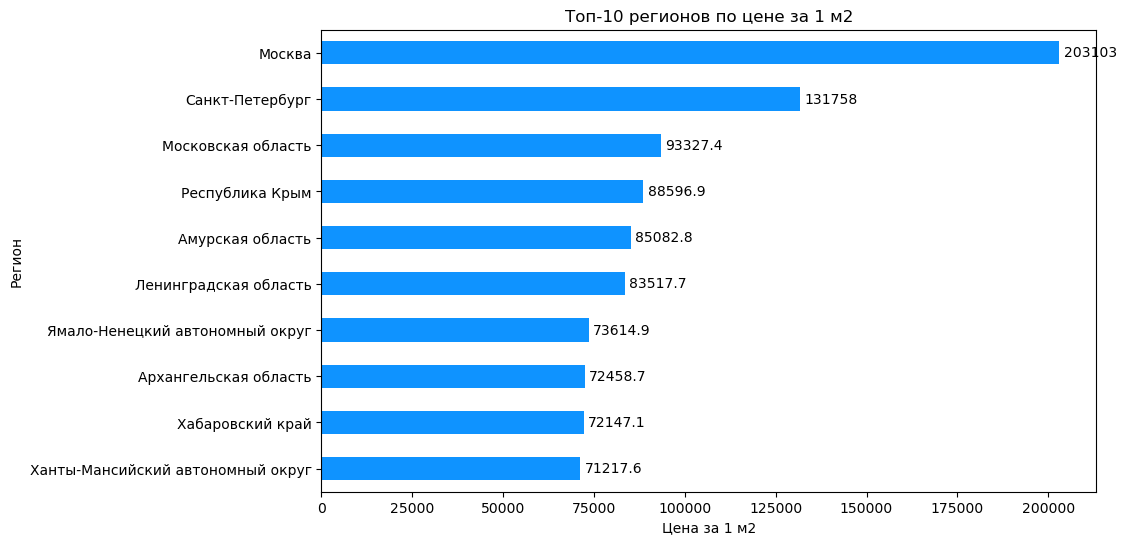

In [7]:
#визуализируем
ax = region_price_for_1m2.sort_values(by='price_for_1m2').tail(10).plot(kind='barh', figsize=(10,6), x='reg_name', y='price_for_1m2', legend=False, color='#0f93ff')
ax.bar_label(ax.containers[0], padding=3)
plt.xlabel('Цена за 1 м2')
plt.ylabel('Регион')
plt.title('Топ-10 регионов по цене за 1 м2')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="13"> Вывод

##### Неудивительно, что в топе Москва, Санкт-Петербург, Московская область и Ленинградская область, так как это фактическая и культурная столица России. Почему Республика Крым в рейтинге? Может, потому что это юг? Тогда, где Краснодарский край? Не удивляют Амурская область и Хабаровский край, так как на Даьнем Востоке сама по себе жизнь дорогая. Но вот, что делают в рейтинге Ямало-Ненецкий автономный округ, Архангельская область и Ханты-Мансийский автономный округ, где из-за вечной мерзлоты и сурового климата жизнь местных жителей порой невыносима?

[Вернуться к Навигации](#1)

In [8]:
#посчитаем среднюю цену за 1 м2 для типа рынка
object_type_size_price_for_1m2 = data.groupby('object_type')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
object_type_size_price_for_1m2

,object_type,price_for_1m2
0,1,75876.48
1,11,82857.43


In [9]:
#создадим словарь с расшифровкой
dct_object_type = {1: 'вторичный рынок', 11: 'первичный рынок'}

In [10]:
#применим этот словарь
object_type_size_price_for_1m2['object_type'] = object_type_size_price_for_1m2['object_type'].replace(dct_object_type)
object_type_size_price_for_1m2

,object_type,price_for_1m2
0,вторичный рынок,75876.48
1,первичный рынок,82857.43


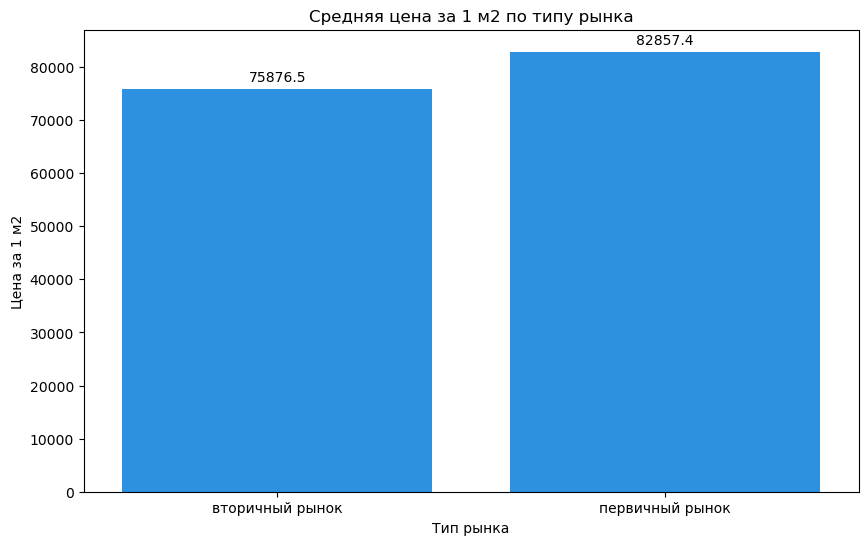

In [11]:
#визуализируем
plt.figure(figsize=(10,6))
ax = sns.barplot(data=object_type_size_price_for_1m2.sort_values(by='price_for_1m2'), x='object_type', y='price_for_1m2', legend=False, color='#0f93ff')
ax.bar_label(ax.containers[0], padding=3)
plt.ylabel('Цена за 1 м2')
plt.xlabel('Тип рынка')
plt.title('Средняя цена за 1 м2 по типу рынка')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="14"> Вывод

##### На графике видно, что цена за 1 м2 на первичном рынке выше, чем на вторичном, что логично

[Вернуться к Навигации](#1)

In [12]:
#посчитаем среднюю цену за 1 м2 по количеству комнат
rooms_price_for_1m2 = data.groupby('rooms')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
rooms_price_for_1m2.head(1)

,rooms,price_for_1m2
0,-1,82678.97


In [13]:
#создадим словарь с расшифровкой
dct_rooms = {-1: 'студия', 1: '1 комната', 2: '2 комнаты', 3: '3 комнаты', 4: '4 комнаты',
             5: '5 комнат', 6: '6 комнат', 7: '7 комнат', 8: '8 комнат', 9: '9 комнат', 10: '10 комнат'}

In [14]:
#применим этот словарь
rooms_price_for_1m2['rooms'] = rooms_price_for_1m2['rooms'].replace(dct_rooms)
rooms_price_for_1m2.head(1)

,rooms,price_for_1m2
0,студия,82678.97


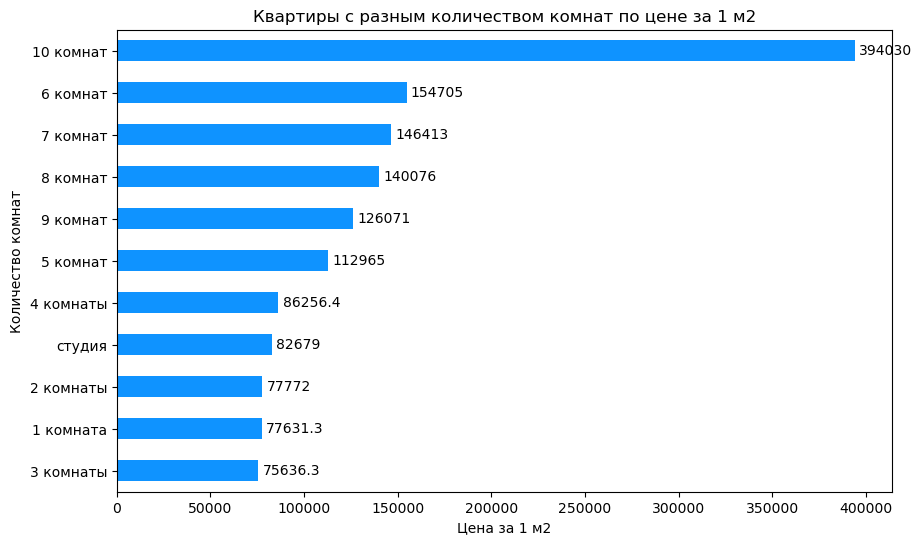

In [15]:
#визуализируем
ax = rooms_price_for_1m2.sort_values(by='price_for_1m2').plot(kind='barh', figsize=(10,6), x='rooms', y='price_for_1m2', legend=False, color='#0f93ff')
ax.bar_label(ax.containers[0], padding=3)
plt.xlabel('Цена за 1 м2')
plt.ylabel('Количество комнат')
plt.title('Квартиры с разным количеством комнат по цене за 1 м2')
plt.show()

In [16]:
data[data['rooms'] == 10]

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room
2160382,132000000,2019-07-22,0,3,6,6,10,335.0,18.0,1,Москва,394029.85,31.7


In [17]:
data['price_for_1m2'].describe()['max']

613385.83

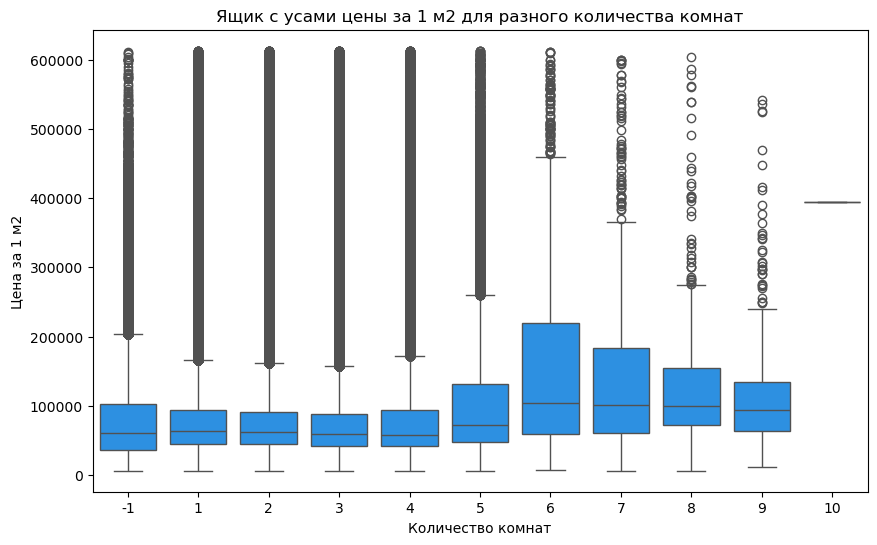

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(y='price_for_1m2', x='rooms', data=data, color='#0f93ff')
plt.xlabel('Количество комнат')
plt.ylabel('Цена за 1 м2')
plt.title('Ящик с усами цены за 1 м2 для разного количества комнат')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="15"> Вывод

##### Первое, что бросилось нам в глаза - почему для 10комнатной квартиры такой невероятный отрыв от остальных. Как оказалось, что такая квартира всего одна после обработки аномалий. Самое главное, что это не выброс! Следущее, что привлекло наше внимание - почему у студии средняя цена за 1 м2 выше, чем для 1комнатых, 2комнатных и 3комнатных? Да и вообще по моей логике должно быть так: цена за 1 м2 растет с увеличенем количества комнат, но засчет роста количества комнат. Но, потом мы пользуемся полученными знаниями за семестр и понимаем, что среднее более чувствительно к выбросам, чем медиана. При построении боксплотов стало видно, что все равно моя логика не со всем работает. Видно, что среди квартир от студий до 4х комнат самая большая медиана для 1комнатных квартир. Делаю предположение, что они самые ходовые. Среди квартир от 5 до 9х комнат самая большая медиана для 6комнатных квартир. Видимо, именно 6 комнат - это оптимально для многокомнатых квартир.

[Вернуться к Навигации](#1)

In [5]:
#создадим столбец с годом
data['year'] = data['date'].dt.year
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018


In [20]:
#посчитаем среднюю цену за 1 м2 на весь период
date_price_for_1m2 = data.groupby('date')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
date_price_for_1m2.head(1)

,date,price_for_1m2
0,2018-02-19,73244.55


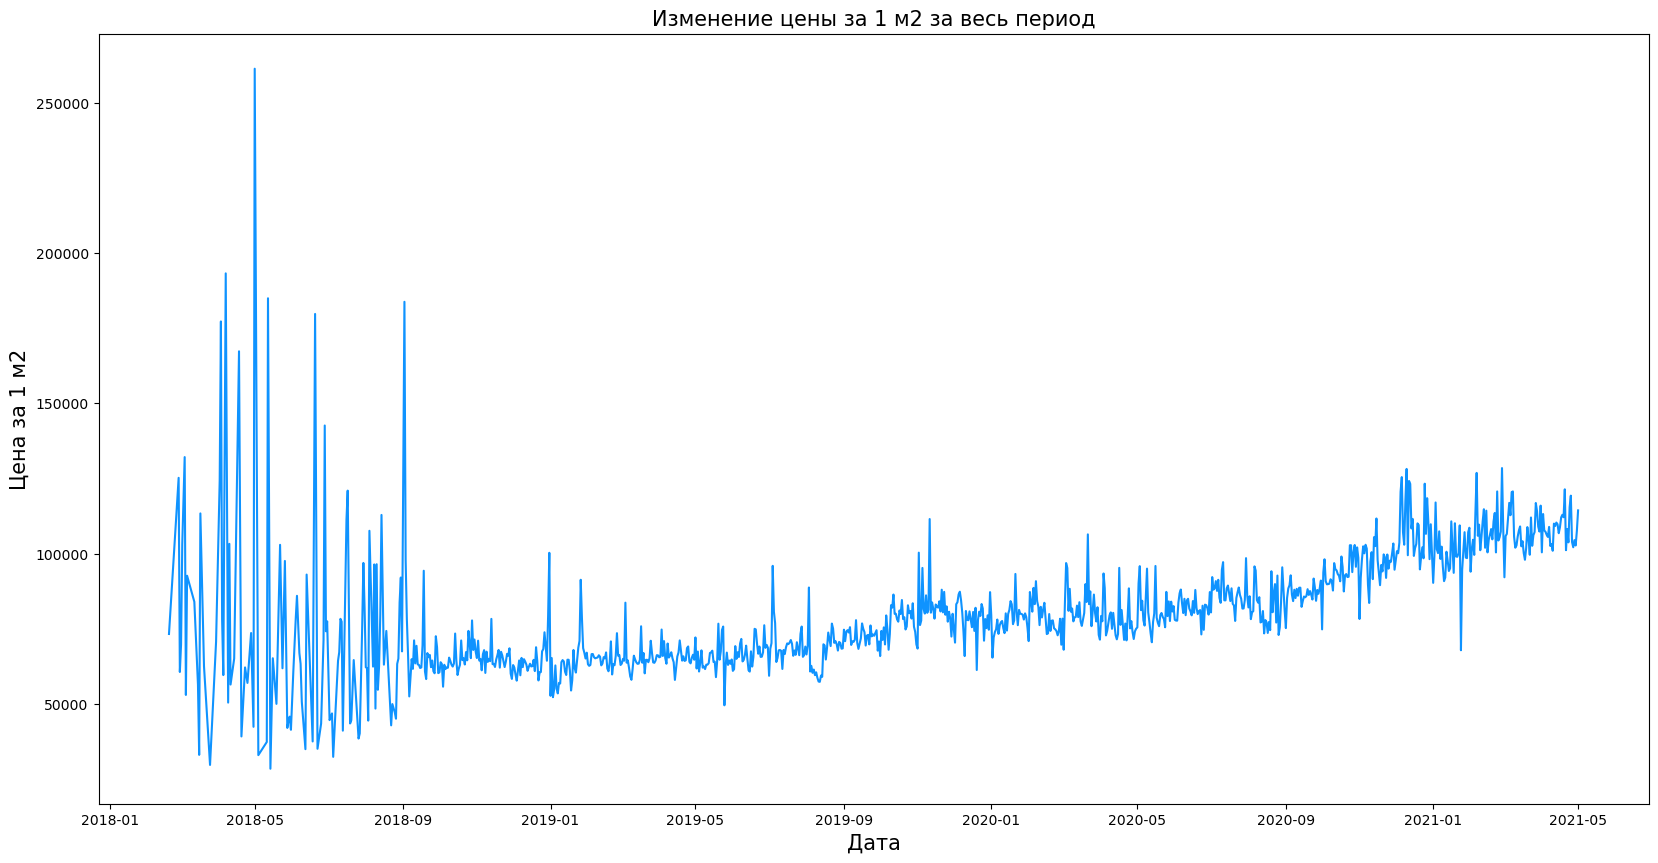

In [21]:
#визуализируем
plt.figure(figsize=(20,10))
sns.lineplot(data=date_price_for_1m2.sort_values(by='price_for_1m2'), x='date', y='price_for_1m2', legend=False, color='#0f93ff')
plt.ylabel('Цена за 1 м2', fontsize=15)
plt.xlabel('Дата', fontsize=15)
plt.title('Изменение цены за 1 м2 за весь период', fontsize=15)
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="16"> Вывод

##### Сразу же бросается в глаза, что в 2018 году со средней ценой творится, что-то странное. Поискав информацию в интернете, стало ясно, что в 2018 году еще действовал договор долевого участия, то есть квартиру можно было купить еще на этапе строительства. Поэтому цена для одинаковых квартир, но на разном этапе строительства так сильно могла отличаться, что и выражается на графике для 2018 года. В 2018 году приняли закон о запрете ДДУ на фоне обмана дольщиков крупного застройщика Urban Group. Закон был принят для избежания таких ситуаций, когда средства на строительства дома у застройщика появляется по мере строительства, а не заранее. Так на фоне высокой конкуренции спрос на твой строящийся объект может не оправдаться ожидаемый, поэтому и денег на дальнейшее строительство может не хватить. Далее ситуация на графике выровнялась и виден устойчивый рост средней цены за 1 м2, что логично

[Вернуться к Навигации](#1)

In [22]:
#посчитаем среднюю цену за 1 м2 по годам
year_price_for_1m2 = data.groupby('year')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
year_price_for_1m2.head(1)

,year,price_for_1m2
0,2018,66094.43


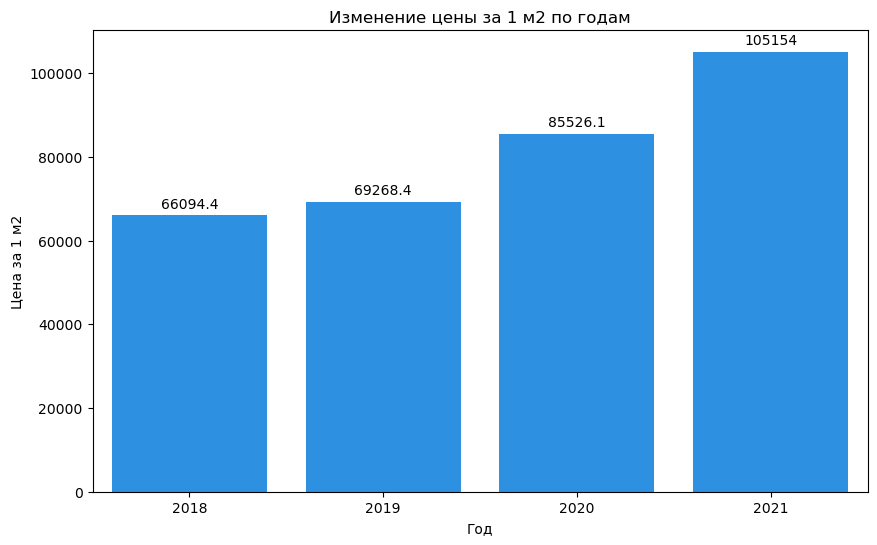

In [23]:
#визуализируем
plt.figure(figsize=(10,6))
ax = sns.barplot(data=year_price_for_1m2.sort_values(by='price_for_1m2'), x='year', y='price_for_1m2', legend=False, color='#0f93ff')
ax.bar_label(ax.containers[0], padding=3)
plt.ylabel('Цена за 1 м2')
plt.xlabel('Год')
plt.title('Изменение цены за 1 м2 по годам')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="17"> Вывод

##### На графике видно, что при укрупнении информации о цене за 1 м2 по годам, средняя цена за 1 м2 действительно растет

[Вернуться к Навигации](#1)

In [24]:
#посчитаем среднюю цену за 1 м2 по типу дома
building_type_price_for_1m2 = data.groupby('building_type')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
building_type_price_for_1m2.head(1)

,building_type,price_for_1m2
0,0,82480.95


In [25]:
#создадим словарь с расшифровкой
dct_building_type = {0: 'другое', 1: 'панельный', 2: 'кирпично-монолитный', 3: 'кирпичный', 4: 'блочный', 5: 'деревянный'}

In [26]:
#применим этот словарь
building_type_price_for_1m2['building_type'] = building_type_price_for_1m2['building_type'].replace(dct_building_type)
building_type_price_for_1m2.head(1)

,building_type,price_for_1m2
0,другое,82480.95


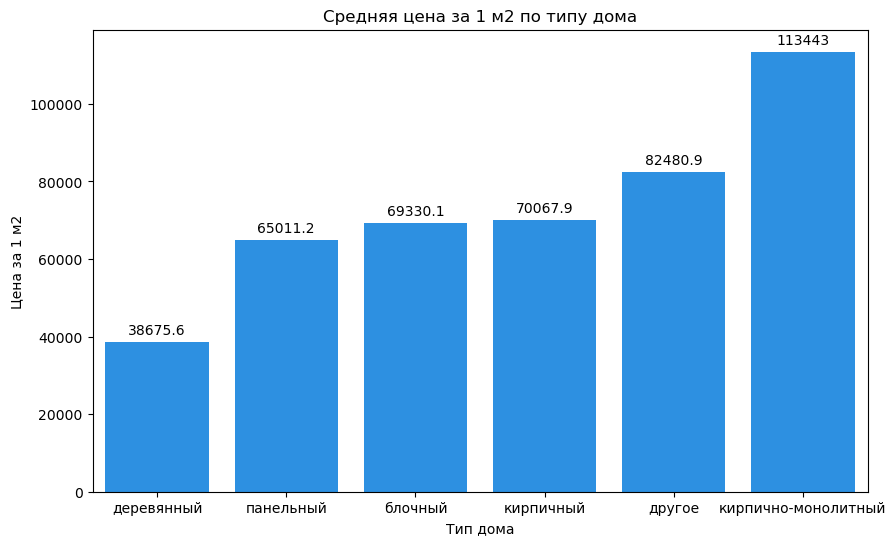

In [27]:
#визуализируем
plt.figure(figsize=(10,6))
ax = sns.barplot(data=building_type_price_for_1m2.sort_values(by='price_for_1m2'), x='building_type', y='price_for_1m2', legend=False, color='#0f93ff')
ax.bar_label(ax.containers[0], padding=3)
plt.ylabel('Цена за 1 м2')
plt.xlabel('Тип дома')
plt.title('Средняя цена за 1 м2 по типу дома')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="18"> Вывод

##### На графике видно, что чем лучше материал, из которого построен дом, то тем выше цена за 1 м2. Вот только вопрос - что за тип дома "другое"? Также было выяснено, что "кирпично-монолитные" дома присущи для первичного рынка, где цена за 1 м2 выше

[Вернуться к Навигации](#1)

In [28]:
#посчитаем среднюю цену за 1 м2 по номеру этажа
level_price_for_1m2 = data.groupby('level')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
level_price_for_1m2.head(1)

,level,price_for_1m2
0,1,60514.15


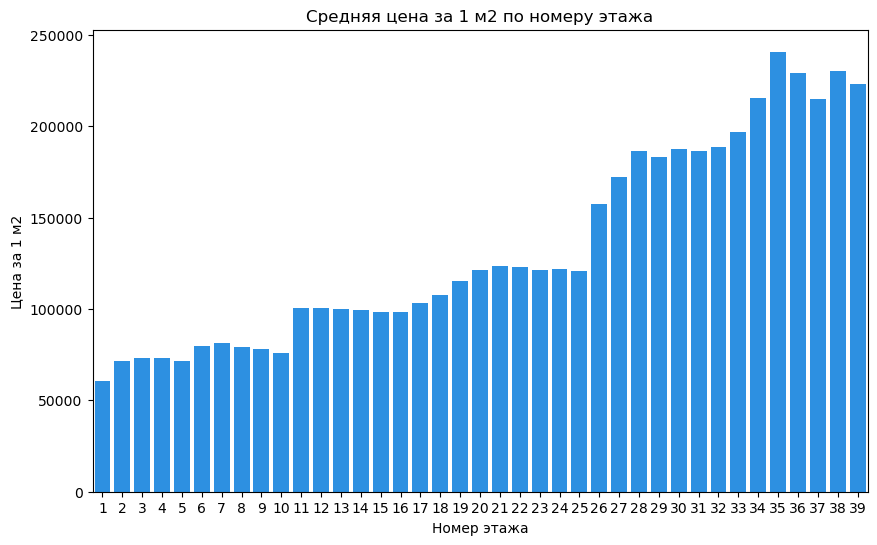

In [29]:
#визуализируем
plt.figure(figsize=(10,6))
ax = sns.barplot(data=level_price_for_1m2.sort_values(by='price_for_1m2'), x='level', y='price_for_1m2', legend=False, color='#0f93ff')
plt.ylabel('Цена за 1 м2')
plt.xlabel('Номер этажа')
plt.title('Средняя цена за 1 м2 по номеру этажа')
plt.show()

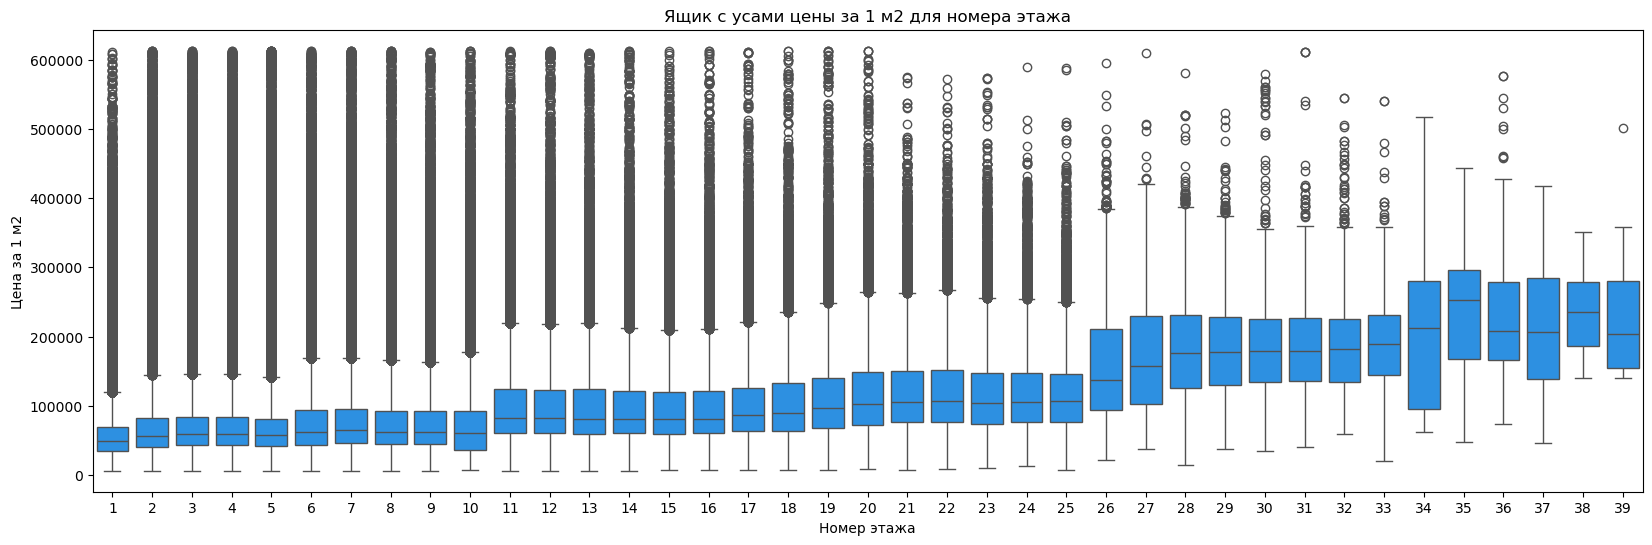

In [30]:
plt.figure(figsize=(20, 6))
sns.boxplot(y='price_for_1m2', x='level', data=data, color='#0f93ff')
plt.xlabel('Номер этажа')
plt.ylabel('Цена за 1 м2')
plt.title('Ящик с усами цены за 1 м2 для номера этажа')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="19"> Вывод

##### Видно, что цена за 1 м2 растет с увеличением номера этажа, Но если поделить номера этажей на промежутки, то видно, что самый высокий 1 м2 на промежутке для квартир выше средней этажности. На промежутке до 10 этажа цена за 1 м2 выше у 6 и 7 этажей, для промежутка до 26 этажа цена за 1 м2 выше у 21 и 22 этажей, на промежутке до 39 этажа цена за 1 м2 выше у 35 этажа. При построении боксплотов наблюдается такая же тенденция. Еще рост цены за 1 м2 можно объяснить тем, что многоэтажные дома строятся для первичного рынка, где цена за 1 м2 выше

[Вернуться к Навигации](#1)

In [31]:
#посчитаем среднюю цену за 1 м2 по количеству этажей в доме
levels_price_for_1m2 = data.groupby('levels')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
levels_price_for_1m2.head(1)

,levels,price_for_1m2
0,1,34895.24


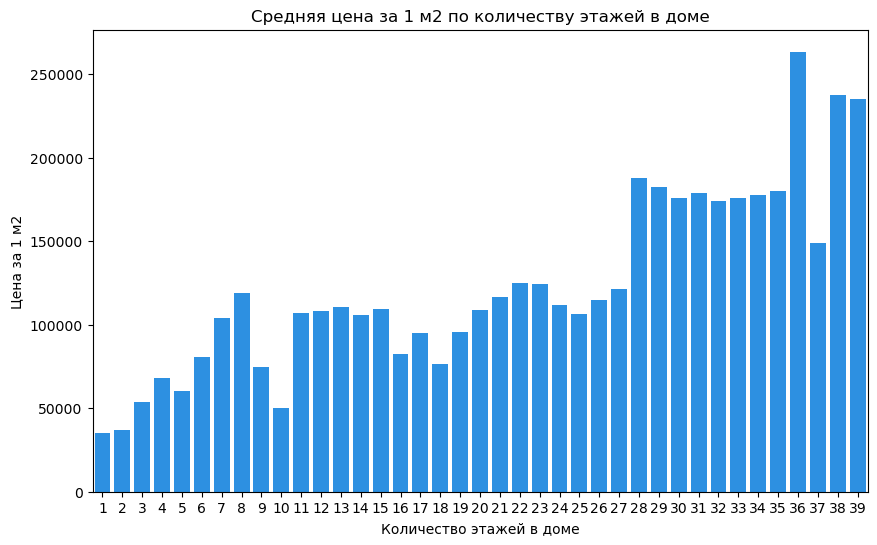

In [32]:
#визуализируем
plt.figure(figsize=(10,6))
ax = sns.barplot(data=levels_price_for_1m2.sort_values(by='price_for_1m2'), x='levels', y='price_for_1m2', legend=False, color='#0f93ff')
plt.ylabel('Цена за 1 м2')
plt.xlabel('Количество этажей в доме')
plt.title('Средняя цена за 1 м2 по количеству этажей в доме')
plt.show()

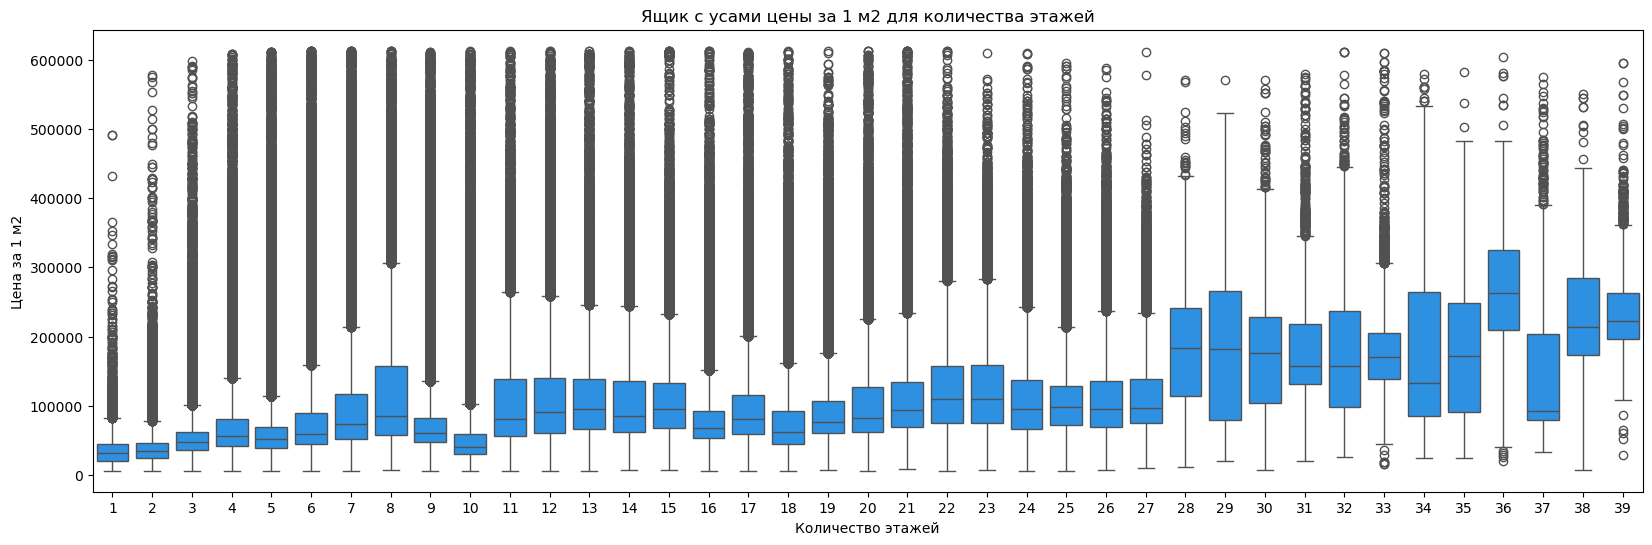

In [33]:
plt.figure(figsize=(20, 6))
sns.boxplot(y='price_for_1m2', x='levels', data=data, color='#0f93ff')
plt.xlabel('Количество этажей')
plt.ylabel('Цена за 1 м2')
plt.title('Ящик с усами цены за 1 м2 для количества этажей')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="20"> Вывод

##### Можно только предположить, с чем связана такая динамика. Для малоэтажных домов: низкая цена за 1м2 может быть связана с недостатками, такими как близость к улице, шум и плохой вид из окон. Странно, что 7 и 8этажные дома сравнялись со средней этажностью. Для среднеэтажных домов: более высокая цена за 1 м2 обусловлена комфортным расположением — достаточно далеко от шума улицы, но не слишком высоко, что может быть удобно для жителей. Для многоэтажных домов: рост цены за 1 м2 может быть связан с лучшими видами, приватностью, престижем жилья на высоких этажах, а также тем, что такие дома присущи первичному рынку, где цена за 1 м2 выше


[Вернуться к Навигации](#1)

In [6]:
#создадим столбец с закодированным типом этажа
data['level_is'] = data.apply(lambda x: -1 if x['level'] == 1 else (1 if x['level'] == x['levels'] else 0), axis=1)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0


In [217]:
#посчитаем среднюю цену за 1 м2 для типа этажа
level_is_price_for_1m2 = data.groupby('level_is')['price_for_1m2'].apply(lambda x: round(x.mean(), 2)).reset_index()
level_is_price_for_1m2

,level_is,price_for_1m2
0,1,60514.15
1,2,65281.23
2,3,82998.69


In [218]:
#создадим словарь с расшифровкой
dct_level_is = {-1: 'первый этаж', 1: 'крайний этаж', 0: 'средний этаж'}

In [219]:
#применим этот словарь
level_is_price_for_1m2['level_is'] = level_is_price_for_1m2['level_is'].replace(dct_level_is)
level_is_price_for_1m2

,level_is,price_for_1m2
0,крайний этаж,60514.15
1,2,65281.23
2,3,82998.69


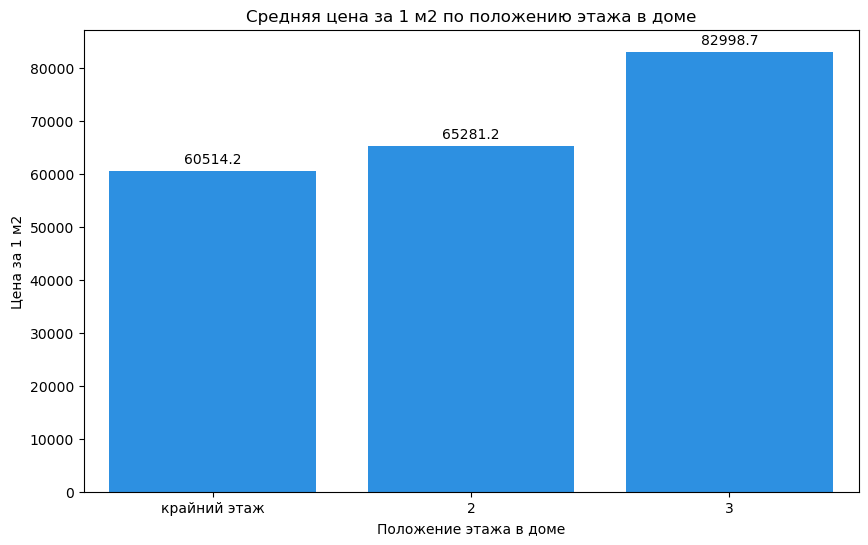

In [220]:
#визуализируем
plt.figure(figsize=(10,6))
ax = sns.barplot(data=level_is_price_for_1m2.sort_values(by='price_for_1m2'), x='level_is', y='price_for_1m2', legend=False, color='#0f93ff')
ax.bar_label(ax.containers[0], padding=3)
plt.ylabel('Цена за 1 м2')
plt.xlabel('Положение этажа в доме')
plt.title('Средняя цена за 1 м2 по положению этажа в доме')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="21"> Вывод

##### При добавлении категориальной переменной - тип этажности, стало теперь точно ясно, что для квартир средней этажности цена за 1 м2 выше, чем для первых и крайних этажей

[Вернуться к Навигации](#1)

## <a class="anchor" id="22"> 5. Исследование периода для выгодной покупки/продажи недвижимости

5. Когда выгодно покупать/продавать объект недвижимости? 

In [221]:
#создаем столбец с номером сезона
data['season'] = (data['date'].dt.month % 12 // 3) + 1
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,3,1,2,19,0.8,0.13


In [222]:
#создаем словарь с номером сезона и его названием
dct_seasons = {1: 'Зима', 2: 'Весна', 3: 'Лето', 4: 'Осень'}

In [223]:
#заменяем номер сезона на его название с помощью replece
data['season'] = data['season'].replace(dct_seasons)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,3,Зима,2,19,0.8,0.13


Рассмотрим отдельно первичный и вторичный рынок

In [224]:
lst_seasons = ['Зима', 'Весна', 'Лето', 'Осень']

In [225]:
#создаем датафрейм, где подсчитана сумма, количество и среднее объявлений в каждом сезоне для вторичного рынка
season_secondary_market = pd.DataFrame(data[data['object_type'] == 1].groupby('season')['price'].agg(['sum', 'count', 'mean']), index=lst_seasons)
season_secondary_market

,sum,count,mean
Зима,3790644192455,924452,4.100423e+06
Весна,4347483008515,984676,4.415141e+06
Лето,2916366069144,716645,4.069471e+06
Осень,4678798877359,1108197,4.221992e+06


Посмотрим, что происходит на первичном рынке

In [ ]:
#создаем датафрейм, где подсчитана сумма, количество и среднее объявлений в каждом сезоне для первичного рынка
season_primary_market = pd.DataFrame(data[data['object_type'] == 11].groupby('season')['price'].agg(['sum', 'count', 'mean']), index=lst_seasons)
season_primary_market

,sum,count,mean
Зима,1911644108491,400742,4.770261e+06
Весна,2107522932106,445527,4.730405e+06
Лето,1338082313514,309121,4.328668e+06
Осень,1969835163536,442744,4.449152e+06


Визуализируем дата фреймы для сравнения первичного и вторичного рынка

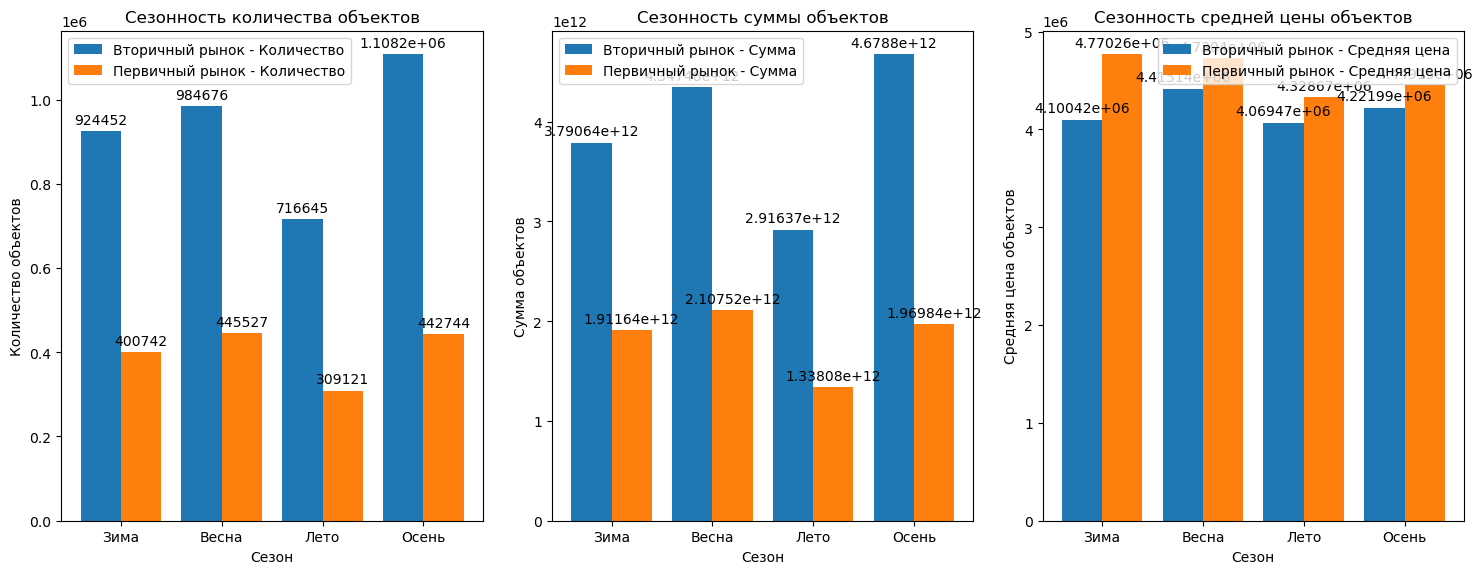

In [228]:
#параметры для графиков
bar_width = 0.4  #ширина столбиков
x = np.arange(len(lst_seasons))  #позиции для столбиков

#создадим фигуру и оси
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 6))

#график для количества объектов
axes[0].bar(x - bar_width/2, season_secondary_market['count'], width=bar_width, label='Вторичный рынок - Количество')
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].bar(x + bar_width/2, season_primary_market['count'], width=bar_width, label='Первичный рынок - Количество')
axes[0].bar_label(axes[0].containers[1], padding=3)
axes[0].set_title('Сезонность количества объектов')
axes[0].set_xlabel('Сезон')
axes[0].set_ylabel('Количество объектов')
axes[0].set_xticks(x)
axes[0].set_xticklabels(lst_seasons)
axes[0].legend()

#график для суммы объектов
axes[1].bar(x - bar_width/2, season_secondary_market['sum'], width=bar_width, label='Вторичный рынок - Сумма')
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].bar(x + bar_width/2, season_primary_market['sum'], width=bar_width, label='Первичный рынок - Сумма')
axes[1].bar_label(axes[1].containers[1], padding=3)
axes[1].set_title('Сезонность суммы объектов')
axes[1].set_xlabel('Сезон')
axes[1].set_ylabel('Сумма объектов')
axes[1].set_xticks(x)
axes[1].set_xticklabels(lst_seasons)
axes[1].legend()

#график для средней цены объектов
axes[2].bar(x - bar_width/2, season_secondary_market['mean'], width=bar_width, label='Вторичный рынок - Средняя цена')
axes[2].bar_label(axes[2].containers[0], padding=3)
axes[2].bar(x + bar_width/2, season_primary_market['mean'], width=bar_width, label='Первичный рынок - Средняя цена')
axes[2].bar_label(axes[2].containers[1], padding=3)
axes[2].set_title('Сезонность средней цены объектов')
axes[2].set_xlabel('Сезон')
axes[2].set_ylabel('Средняя цена объектов')
axes[2].set_xticks(x)
axes[2].set_xticklabels(lst_seasons)
axes[2].legend()

plt.tight_layout()
plt.show()

Детализируем теперь по месяцам

In [229]:
#создаем столбец с номером сезона
data['month'] = data['date'].dt.month
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,3,Зима,2,19,0.8,0.13


In [230]:
#создаем словарь с номером месяца и его названием
dct_months = {1: 'Январь', 2: 'Февраль', 3: 'Март', 4: 'Апрель', 5: 'Май', 6: 'Июнь', 7: 'Июль', 8: 'Август', 9: 'Сентябрь',
              10: 'Октябрь', 11: 'Ноябрь', 12: 'Декабрь'}

In [231]:
#заменяем номер месяца на его название с помощью replece
data['month'] = data['month'].replace(dct_months)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,3,Зима,Февраль,19,0.8,0.13


In [232]:
#создаем список месяцев
lst_months = ['Январь', 'Февраль', 'Март', 'Апрель', 'Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь', 'Ноябрь', 'Декабрь']

In [233]:
#создаем датафрейм, где подсчитана сумма, количество и среднее объявлений в каждом месяце для вторичного рынка
month_secondary_market = pd.DataFrame(data[data['object_type'] == 1].groupby('month')['price'].agg(['sum', 'count', 'mean']), index=lst_months)
month_secondary_market.head(1)

,sum,count,mean
Январь,1015025720918,247880,4.094827e+06


In [ ]:
#создаем датафрейм, где подсчитана сумма, количество и среднее объявлений в каждом месяце для вторичного рынка
month_primary_market = pd.DataFrame(data[data['object_type'] == 11].groupby('month')['price'].agg(['sum', 'count', 'mean']), index=lst_months)
month_primary_market.head(1)

,sum,count,mean
Январь,437890390703,101102,4.331174e+06


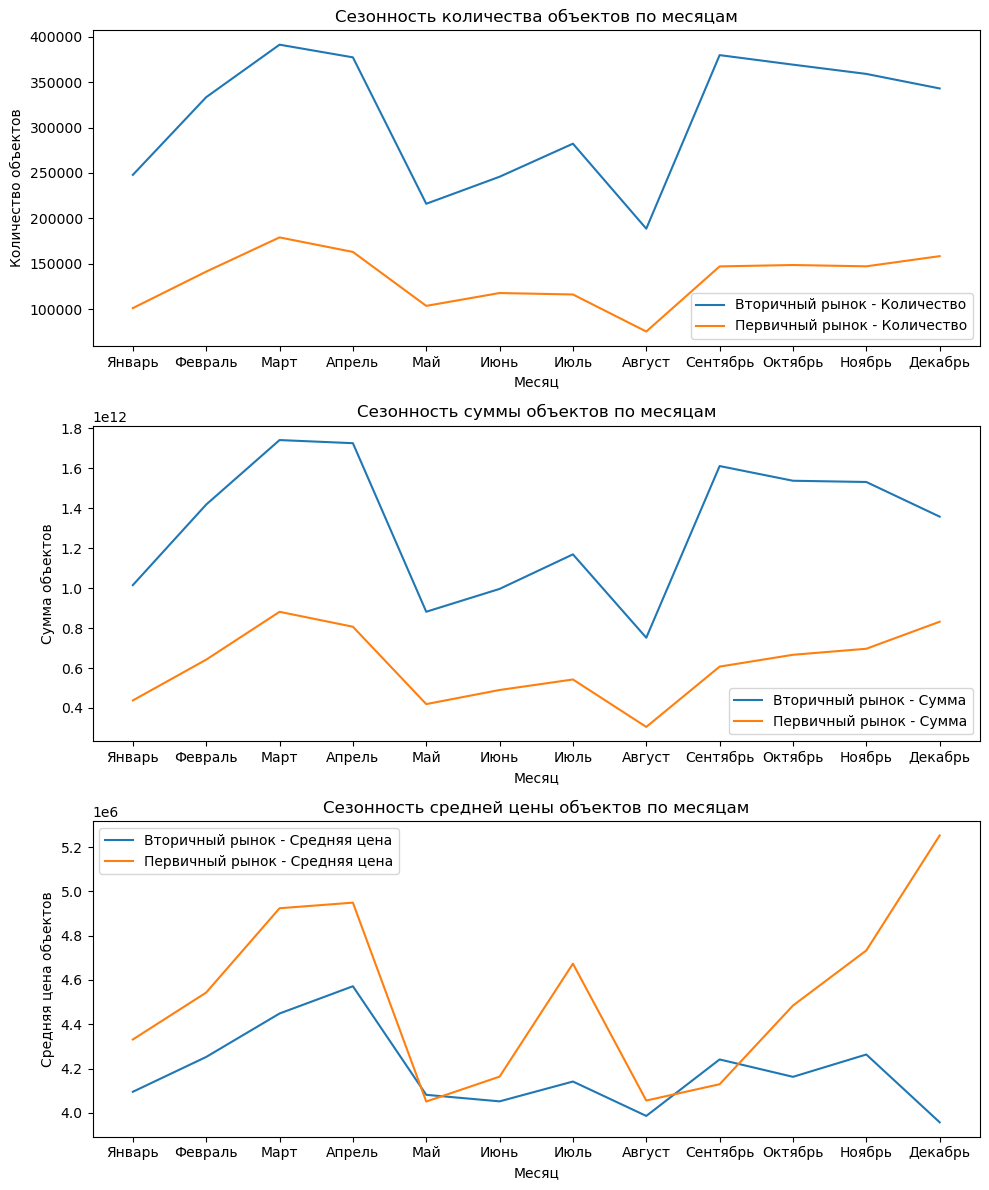

In [237]:
#создадим фигуру и оси
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 12))

#график для количества объектов
sns.lineplot(ax=axes[0], data=month_secondary_market['count'], label='Вторичный рынок - Количество')
sns.lineplot(ax=axes[0], data=month_primary_market['count'], label='Первичный рынок - Количество')
axes[0].set(title='Сезонность количества объектов по месяцам', xlabel='Месяц', ylabel='Количество объектов')
axes[0].legend()

#график для суммы объектов
sns.lineplot(ax=axes[1], data=month_secondary_market['sum'], label='Вторичный рынок - Сумма')
sns.lineplot(ax=axes[1], data=month_primary_market['sum'], label='Первичный рынок - Сумма')
axes[1].set(title='Сезонность суммы объектов по месяцам', xlabel='Месяц', ylabel='Сумма объектов')
axes[1].legend()

#график для средней цены объектов
sns.lineplot(ax=axes[2], data=month_secondary_market['mean'], label='Вторичный рынок - Средняя цена')
sns.lineplot(ax=axes[2], data=month_primary_market['mean'], label='Первичный рынок - Средняя цена')
axes[2].set(title='Сезонность средней цены объектов по месяцам', xlabel='Месяц', ylabel='Средняя цена объектов')
axes[2].legend()

#отступы между графиками
plt.tight_layout()
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="23"> Вывод

##### При анализе периодов для покупки/продажи мы рассматривали отдельно первичный и вторичный рынок. Сначала мы исследовали по временам года, а далее по месяцам. На графиках видно, что для каждого рынка есть одинаковые тенденции для количества объявлений и их суммы. Неудивительно, что количество объявлений для вторичного рынка больше, чем для первичного. Соответственно, это прослеживается и для суммы объявлений. Из отличий можно выделить, что для вторичного рынка пик активности - осень, далее весна, потом зима и в конце лето, а вот для первичного - весна и осень примерно равны, далее идет зима и также в конце лето. Но при этом, средняя цена объявления выше для первичного рынка, что отчасти логично. Для первичного рынка средняя цена выше зимой и весной, потом осенью и далее летом. Для вторичного сначала идет весна, далее осень, потом зима и в конце лето. В итоге, для первичного рынка покупать недвижимость лучше летом, как и для вторичного. А вот продавать недвижимость для первичного рынка выгоднее зимой и весной, а для вторичного - весной <br> <br>При разбиении по месяцам становится понятнее, когда стоит продавать/покупать недвижимость. Динамика количества и суммы объявлений для первичного и вторичного рынка практически не отличается, только для первичного рынка количество и сумма объявлений под конец года чуть-чуть растет, а не падает, как для вторичного рынка. Интереснее всего смотреть, как изменяется средняя цена объявления. Например, в мае и сентябре средняя цена для вторичного рынка выше, чем для первичного. Остальная динамика соответствует динамике количества и суммы объявлений. Таким образом, для первичного рынка покупать недвижимость лучше в мае, для вторичного - в декабре. А вот продавать недвижимость для первичного рынка выгоднее в декабре, а для вторичного - в апреле


[Вернуться к Навигации](#1)

## <a class="anchor" id="24"> 6. Исследование от каких признаков зависит стоимость объекта недвижимости. Поиск скрытых закономерностей

6. Определите от каких признаков зависит стоимость объекта недвижимости. Найдите скрытые закономерности.

Попытаемся вытащить максимум из наших данных

In [201]:
#заново создаем столбец с номером сезона
data['season'] = (data['date'].dt.month % 12 // 3) + 1
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,3,1,2,19,0.8,0.13


In [54]:
#заново создаем столбец с номером месяца
data['month'] = data['date'].dt.month
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0,1,2


In [9]:
#создаем столбец с номером дня
data['day'] = data['date'].dt.day
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0,1,2,19


Попробуем создать такие интересные метрики для поиска скрытых взаимосвязей

In [10]:
data['level_ratio'] = round(data['level'] / data['levels'], 2)
data['kitchen_area_ratio'] = round(data['kitchen_area'] / data['area'], 2) 
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,14,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0,1,2,19,0.8,0.13


Посмотрим как коррелируют другие столбцы с ценой

In [57]:
#выведем только столбик для цены
data[['price', 'date', 'code', 'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area', 'object_type', 'area_for_room', 'year', 'level_is', 
      'season', 'month', 'level_ratio', 'kitchen_area_ratio', 'day']].corr(method='spearman')['price'].sort_values(ascending=False)

price                 1.000000
area                  0.512970
kitchen_area          0.431528
rooms                 0.399935
levels                0.379168
level                 0.264931
date                  0.222018
year                  0.208653
level_is              0.036746
building_type         0.028999
object_type           0.023888
day                   0.010013
area_for_room         0.006758
kitchen_area_ratio   -0.014565
month                -0.016242
season               -0.021225
level_ratio          -0.046608
code                 -0.458899
Name: price, dtype: float64

Построим диаграммы рессевания для видуализации аналитического вида связи

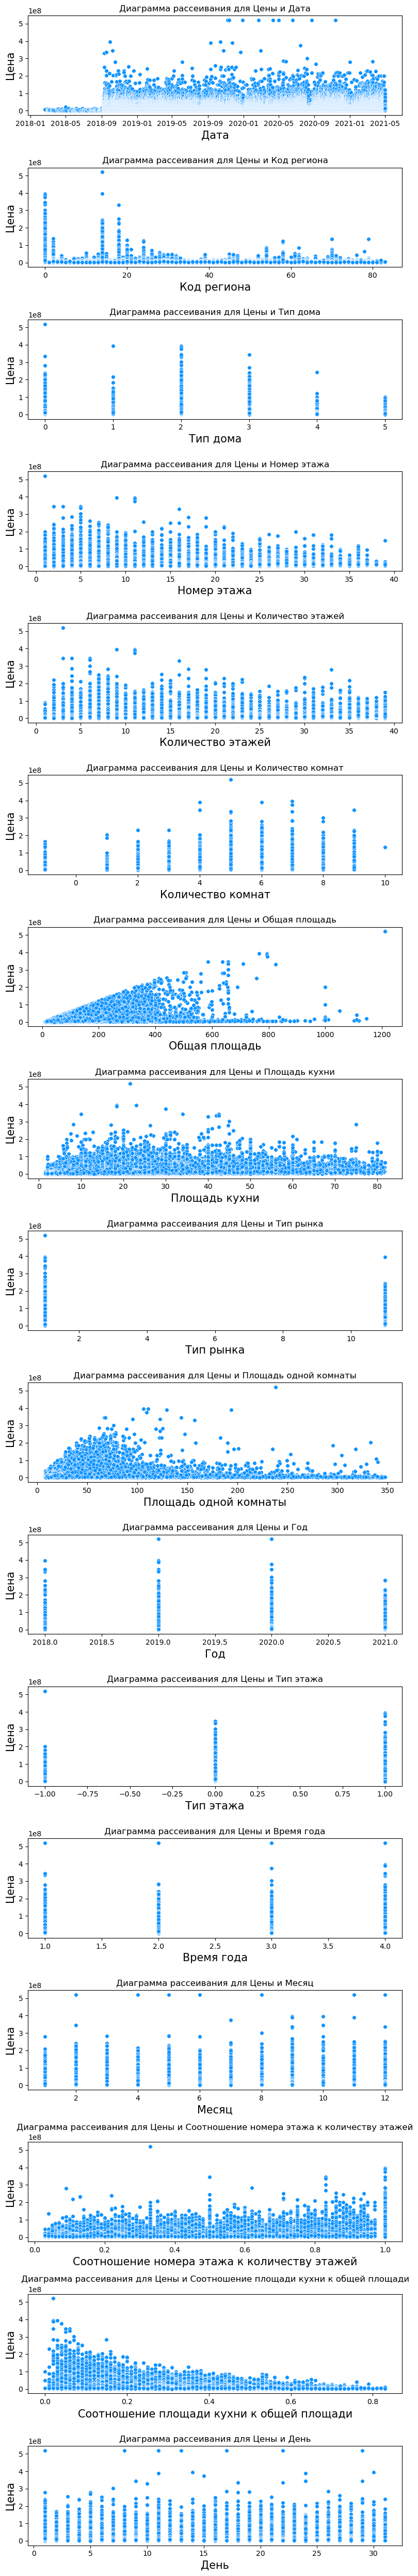

In [58]:
#cписок столбцов
columns = ['date', 'code', 'building_type', 'level', 'levels', 'rooms',
       'area', 'kitchen_area', 'object_type', 'area_for_room', 'year', 'level_is', 'season', 'month', 'level_ratio', 'kitchen_area_ratio', 'day']

#cписок названий столбцов на русском
names = ['Дата', 'Код региона', 'Тип дома', 'Номер этажа', 'Количество этажей', 'Количество комнат', 'Общая площадь', 'Площадь кухни', 'Тип рынка', 'Площадь одной комнаты', 
'Год', 'Тип этажа', 'Время года', 'Месяц', 'Соотношение номера этажа к количеству этажей', 'Соотношение площади кухни к общей площади', 'День']

#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=len(columns), ncols=1, figsize=(8, 50))

for ax, col, name in zip(axes, columns, names): 
       sns.scatterplot(data=data, x=col, y='price', ax=ax, s=30, color='#0f93ff')
       ax.set_xlabel(name, fontsize=15)
       ax.set_ylabel('Цена', fontsize=15)
       ax.set_title(f'Диаграмма рассеивания для Цены и {name}')

plt.tight_layout()
plt.show()

И тут меня осенило, что коды регионов, тип дома, тип рынка и тип этажа закодированы, но не имеют логического смысла, поэтому я решил перезаписать их по мере роста средней цены

In [11]:
#рассчитаем среднюю цену для каждого кода региона
code_mean_price = data.groupby('code')['price'].mean().sort_values()

#создадим словарь: старый код: новый код
code_mapping = {old_code: new_code for new_code, old_code in enumerate(code_mean_price.index, start=1)}

#применим словарь к столбцу
data['code'] = data['code'].map(code_mapping)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,1,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0,1,2,19,0.8,0.13


In [12]:
#проверим
data.groupby('code')['price'].mean()

code
1     1.761213e+06
2     1.890257e+06
3     1.968066e+06
4     1.986960e+06
5     2.033689e+06
          ...     
80    4.812514e+06
81    5.203460e+06
82    5.584587e+06
83    8.075415e+06
84    1.200869e+07
Name: price, Length: 84, dtype: float64

In [13]:
#рассчитаем среднюю цену для каждого типа дома
building_type_mean_price = data.groupby('building_type')['price'].mean().sort_values()

#создадим словарь: старый код: новый код
building_type_mapping = {old_code: new_code for new_code, old_code in enumerate(building_type_mean_price.index, start=1)}

#применим словарь к столбцу
data['building_type'] = data['building_type'].map(building_type_mapping)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0,1,2,19,0.8,0.13


In [14]:
#проверим
data.groupby('building_type')['price'].mean()

building_type
1    1.923385e+06
2    3.229483e+06
3    3.450105e+06
4    3.970559e+06
5    5.069229e+06
6    6.716848e+06
Name: price, dtype: float64

In [15]:
#рассчитаем среднюю цену для каждого типа рынка
object_type_mean_price = data.groupby('object_type')['price'].mean().sort_values()

#создадим словарь: старый код: новый код
object_type_mapping = {old_code: new_code for new_code, old_code in enumerate(object_type_mean_price.index, start=1)}

#применим словарь к столбцу
data['object_type'] = data['object_type'].map(object_type_mapping)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,0,1,2,19,0.8,0.13


In [16]:
#проверим
data.groupby('object_type')['price'].mean()

object_type
1    4.213556e+06
2    4.584775e+06
Name: price, dtype: float64

In [17]:
#рассчитаем среднюю цену для каждого типа рынка
level_is_mean_price = data.groupby('level_is')['price'].mean().sort_values()

#создадим словарь: старый код: новый код
level_is_mapping = {old_code: new_code for new_code, old_code in enumerate(level_is_mean_price.index, start=1)}

#применим словарь к столбцу
data['level_is'] = data['level_is'].map(level_is_mapping)
data.head(1)

,price,date,code,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_for_1m2,area_for_room,year,level_is,season,month,day,level_ratio,kitchen_area_ratio
0,6050000,2018-02-19,83,2,8,10,3,82.6,10.8,1,Санкт-Петербург,73244.55,23.93,2018,3,1,2,19,0.8,0.13


In [18]:
#проверим
data.groupby('level_is')['price'].mean()

level_is
1    2.903025e+06
2    3.686957e+06
3    4.666424e+06
Name: price, dtype: float64

Проверим, что изменилось

In [67]:
#выведем только столбик для цены
data[['price', 'date', 'code', 'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area', 'object_type', 'area_for_room', 'year', 
      'level_is', 'season', 'month', 'level_ratio', 'kitchen_area_ratio', 'day']].corr(method='spearman')['price'].sort_values(ascending=False)

price                 1.000000
code                  0.596725
area                  0.512970
kitchen_area          0.431528
rooms                 0.399935
levels                0.379168
building_type         0.331142
level                 0.264931
date                  0.222018
level_is              0.219687
year                  0.208653
object_type           0.023888
day                   0.010013
area_for_room         0.006758
kitchen_area_ratio   -0.014565
month                -0.016242
season               -0.021225
level_ratio          -0.046608
Name: price, dtype: float64

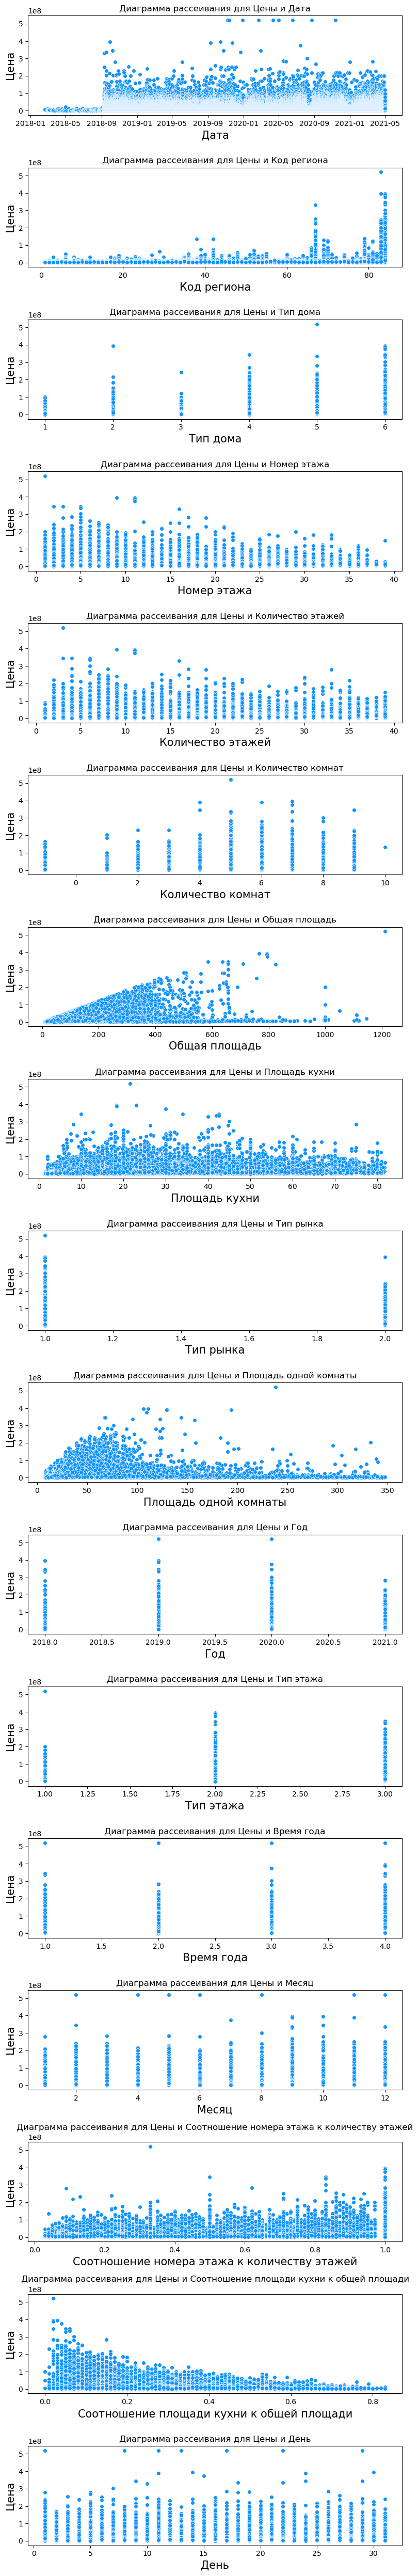

In [68]:
#cписок столбцов
columns = ['date', 'code', 'building_type', 'level', 'levels', 'rooms',
       'area', 'kitchen_area', 'object_type', 'area_for_room', 'year', 'level_is', 'season', 'month', 'level_ratio', 'kitchen_area_ratio', 'day']

#cписок названий столбцов на русском
names = ['Дата', 'Код региона', 'Тип дома', 'Номер этажа', 'Количество этажей', 'Количество комнат', 'Общая площадь', 'Площадь кухни', 'Тип рынка', 'Площадь одной комнаты', 
'Год', 'Тип этажа', 'Время года', 'Месяц', 'Соотношение номера этажа к количеству этажей', 'Соотношение площади кухни к общей площади', 'День']

#cоздаем подграфики для каждого столбца в одну строку
fig, axes = plt.subplots(nrows=len(columns), ncols=1, figsize=(8, 50))

for ax, col, name in zip(axes, columns, names): 
       sns.scatterplot(data=data, x=col, y='price', ax=ax, s=30, color='#0f93ff')
       ax.set_xlabel(name, fontsize=15)
       ax.set_ylabel('Цена', fontsize=15)
       ax.set_title(f'Диаграмма рассеивания для Цены и {name}')
       
plt.tight_layout()
plt.show()

Все-таки у нас много нелинейных взаимосвязей, поэтому попробуем оценить важность остальных признаков с помощью модели Случайного Леса, которая учитывает и нелийные взаимосвязи

In [69]:
#определимся с переменными
x = data[['code', 'building_type', 'level', 'levels', 'rooms',
       'area', 'kitchen_area', 'object_type', 'area_for_room', 'year', 'level_is', 'season', 'month', 'level_ratio', 'kitchen_area_ratio', 'day']]
y = data['price']

In [70]:
#разделим данных на обучающую и тестовую выборки
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [71]:
#создадим модель случайный лес
model = RandomForestRegressor(n_estimators=100, random_state=0)

#обучим ее на наших данных
model.fit(x_train, y_train)

RandomForestRegressor(random_state=0)

In [72]:
#делаем прогноз
y_pred = model.predict(x_test)

In [ ]:
#посчитаем разные метрики, чтобы оценить качество нашей модели
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Среднеквадратическая ошибка (MSE):", mse)
print("Среднеквадратическая ошибка (RMSE):", rmse)
print("Средняя абсолютная ошибка (MAE):", mae)
print("Средняя абсолютная процентная ошибка (MAPE):", mape)
print("Коэффициент детерминации (R^2):", r2)

Среднеквадратическая ошибка (MSE): 3275312559660.985
Среднеквадратическая ошибка (RMSE): 1809782.461971876
Средняя абсолютная ошибка (MAE): 685895.9413616478
Средняя абсолютная ошибка  (MAPE): 0.1795726775361086
Коэффициент детерминации (R^2): 0.8796071528389786


Модель имеет адекватную точность для наших данных и хорошо объясняет вариацию цены объектов недвижимости

In [74]:
#оценим важность признаков
importance = model.feature_importances_
feature_importance = pd.Series(importance, index=x.columns).sort_values(ascending=False)

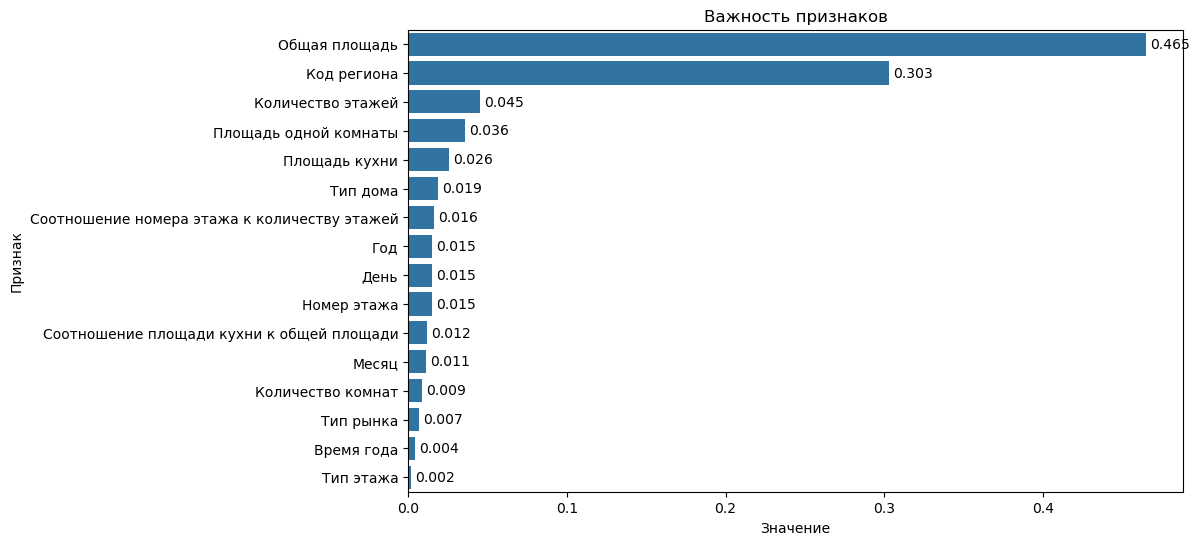

In [75]:
#список названий признаков на русском
names = ['Общая площадь', 'Код региона', 'Количество этажей', 'Площадь одной комнаты', 'Площадь кухни', 'Тип дома', 'Соотношение номера этажа к количеству этажей', 
              'Год', 'День', 'Номер этажа', 'Соотношение площади кухни к общей площади', 'Месяц', 'Количество комнат', 'Тип рынка', 'Время года', 'Тип этажа']

#"переведем" признаки на русский
feature_importance.index = names

#визуализируем
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=np.round(feature_importance.values, 3), y=feature_importance.index)
ax.bar_label(ax.containers[0], padding=3)
plt.xlabel('Значение')
plt.ylabel('Признак')
plt.title('Важность признаков')
plt.show()

[Вернуться к Навигации](#1)

## <a class="anchor" id="25"> Вывод

##### Важность признаков, от которых зависит цена недвижимости была оценена с помощью коэффициента корреляции Спирмана и построения модели Случайный Лес. Корреляция Спирмана больше подвержена наличию лиейности взаимосвязи, поэтому, на нашему мнению лучше смотреть на модель, которая учитывает нелинейные связи. Топ-5 важности признаков для модели - общая площадь, код региона, количество этажей, площадь одной комнаты (эта метрика связана с общей площадью) и площадь кухни. Топ-5 для корреляции Спирмана - код региона, общая площадь, площадь кухни и количество комнат. Как видно, 3 из 5 признаков совпадает. Для поиска скрытых взаимосвязей были введены метрики - соотношение номера этажа к количеству этажей, соотношение площади кухни к общей площади, также были рассмотрены признаки, введенные по мере выполнения работы - площадь одной комнаты, год, день, месяц, время года. К сожалению, с помощью этих метрик скрытых взаимосвязей не было обнаружено 

[Вернуться к Навигации](#1)

## <a class="anchor" id="26"> 7. Выдвижение собственной гипотезы и ее проверка

7. Выдвинете и проверьте собственную гипотезу статистическими методами.

In [178]:
data_low_floor = data[data['level_ratio'] < 0.5]['price_for_1m2']
data_high_floor = data[data['level_ratio'] >= 0.5]['price_for_1m2']

H0: Статистически значимая разница в цене за 1м2 объектов недвижимости нижней и верхней этажности ОТСУТСТВУЕТ<br>
H1: Статистически значимая разница в цене за 1м2 объектов недвижимости нижней и верхней этажности ПРИСУТСТВУЕТ

Для начала проверим выборки на нормальность

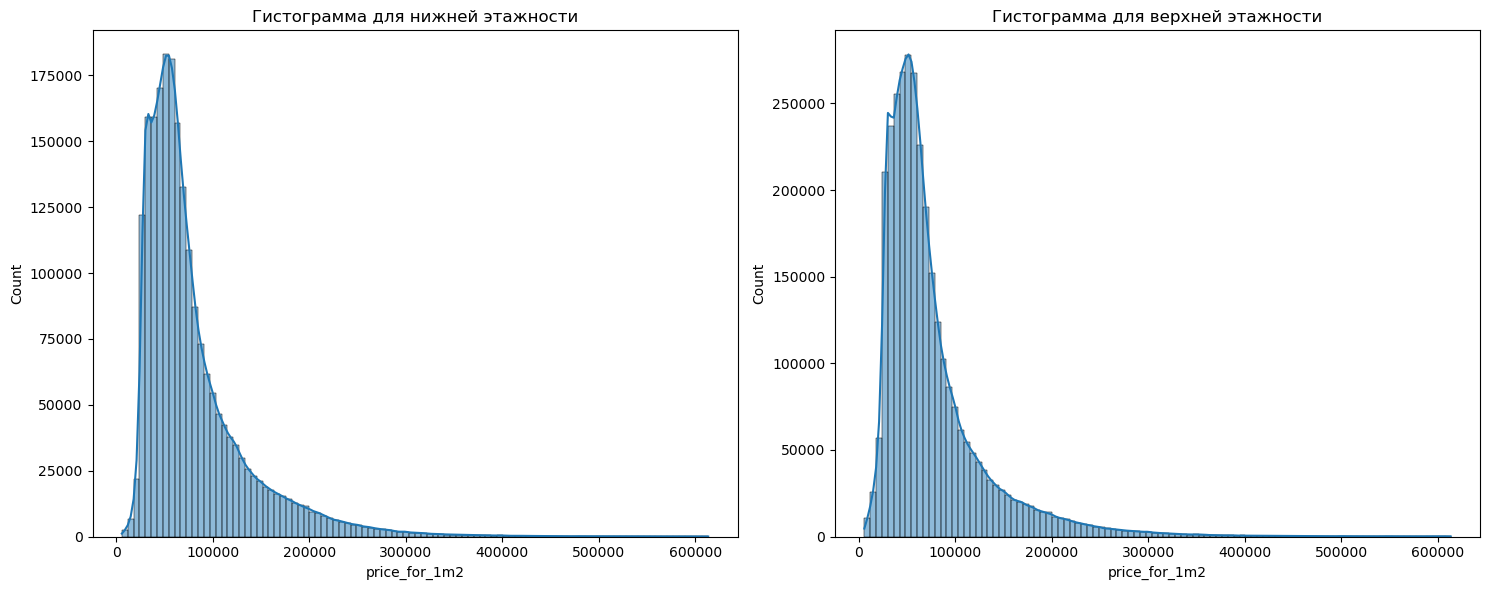

In [179]:
#создадим фигуру и оси
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

#гистограмма для нижней этажности
sns.histplot(data_low_floor, bins=100, kde=True, ax=axes[0])
axes[0].set_title('Гистограмма для нижней этажности')

#гистограмма для верхней этажности
sns.histplot(data_high_floor, bins=100, kde=True, ax=axes[1])
axes[1].set_title('Гистограмма для верхней этажности')

plt.tight_layout()
plt.show()

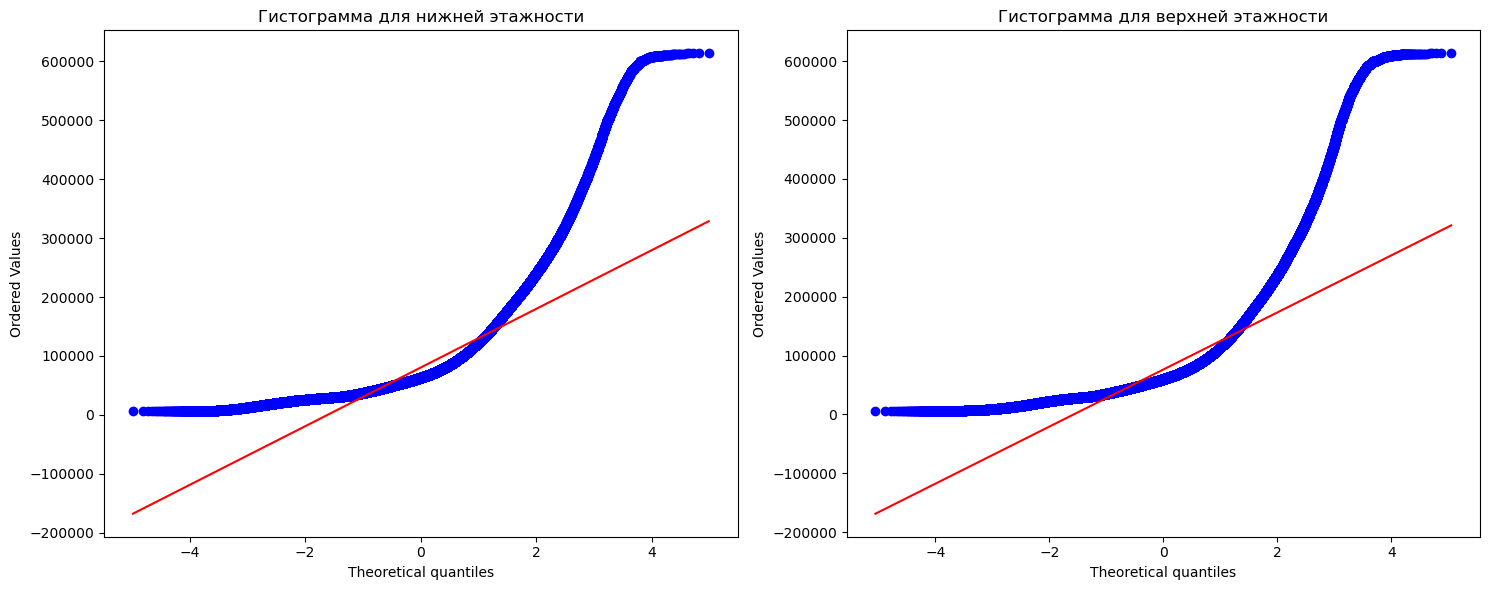

In [ ]:
#создадим фигуру и оси
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

#qqplot для нижней этажности
st.probplot(data_low_floor, dist='norm', plot=axes[0])
axes[0].set_title('Гистограмма для нижней этажности')

#qqplot для верхней этажности
st.probplot(data_high_floor, dist='norm', plot=axes[1])
axes[1].set_title('Гистограмма для верхней этажности')

plt.tight_layout()
plt.show()

</a>H0: Совокупность имеет нормальное распределение<br><br>H1: Совокупность НЕ имеет нормального распределения

In [181]:
#проведем статистический тест Колмогорова-Смирнова
stat, p_value = st.kstest(data_low_floor, 'norm', args=(np.mean(data_low_floor), np.std(data_low_floor)))
alpha = 0.05
if p_value < alpha:
    print(p_value, 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(p_value, 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

0.0 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


In [182]:
#проведем статистический тест Колмогорова-Смирнова
stat, p_value = st.kstest(data_high_floor, 'norm', args=(np.mean(data_high_floor), np.std(data_high_floor)))
alpha = 0.05
if p_value < alpha:
    print(p_value, 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(p_value, 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

0.0 Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения


Так как данные не имеют нормального распределениия, воспользуемся бАкетным тЭстом

In [183]:
#создадим бакеты
bucket_low_floor = np.array([np.mean(np.random.choice(data_low_floor, size=len(data_low_floor) // 1000, replace=False)) for _ in range(1000)])
bucket_high_floor = np.array([np.mean(np.random.choice(data_high_floor, size=len(data_high_floor) // 1000, replace=False)) for _ in range(1000)])

Проверим теперь на нормальность созданные бАкеты

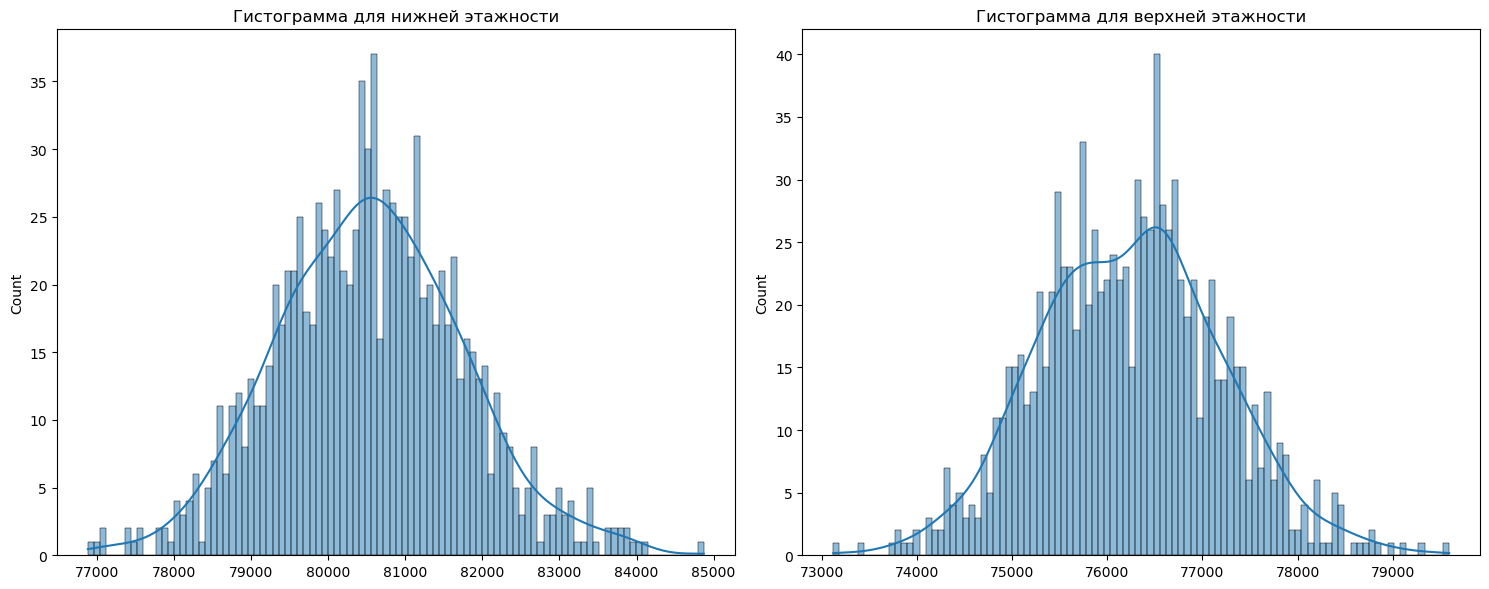

In [184]:
#создадим фигуру и оси
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

#гистограмма для нижней этажности
sns.histplot(bucket_low_floor, bins=100, kde=True, ax=axes[0])
axes[0].set_title('Гистограмма для нижней этажности')

#гистограмма для верхней этажности
sns.histplot(bucket_high_floor, bins=100, kde=True, ax=axes[1])
axes[1].set_title('Гистограмма для верхней этажности')

plt.tight_layout()
plt.show()

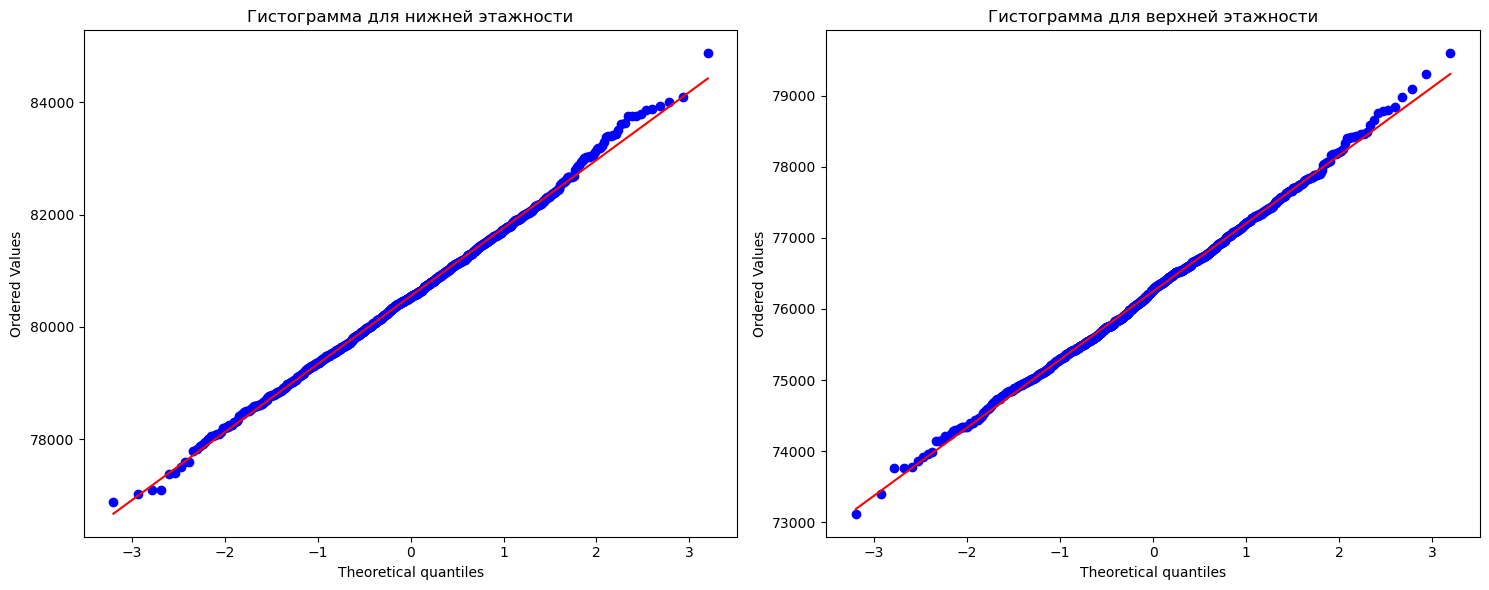

In [ ]:
#создадим фигуру и оси
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

#qqplot для нижней этажности
st.probplot(bucket_low_floor, dist='norm', plot=axes[0])
axes[0].set_title('Гистограмма для нижней этажности')

#qqplot для верхней этажности
st.probplot(bucket_high_floor, dist='norm', plot=axes[1])
axes[1].set_title('Гистограмма для верхней этажности')

plt.tight_layout()
plt.show()

</a>H0: Совокупность имеет нормальное распределение<br><br>H1: Совокупность НЕ имеет нормального распределения

In [191]:
#проведем статистический тест Шапиро-Уилка
stat, p_value = st.shapiro(bucket_low_floor)
alpha = 0.05
if p_value < alpha:
    print(p_value, 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(p_value, 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

0.30854170008437165 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


In [192]:
#проведем статистический тест Шапиро-Уилка
stat, p_value = st.shapiro(bucket_high_floor)
alpha = 0.05
if p_value < alpha:
    print(p_value, 'Отвергаем нулевую гипотезу. Выборка НЕ имеет нормального распределения')
else:
    print(p_value, 'Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение')

0.6006758080751264 Не получилось отвергнуть нулевую гипотезу. Выборка имеет нормальное распределение


Класс! Теперь обе выборки имеют нормальное распределение, так как они еще и независимые, то к ним можно применить параметрический тест `ttest_ind`

</a>H0: Выборки НЕ имеют статистически значимые отличия<br><br>H1: Выборки имеют статистически значимых отличий

In [194]:
#проведем параметрический тест
alpha = 0.05
stat, p_value = st.ttest_ind(bucket_low_floor, bucket_high_floor)
if p_value < alpha:
    print(f'{p_value} Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия')
else:
    print(f'{p_value} Не получилось отвергнуть нулевую гипотезу. Выборки НЕ имеют статистически значимых отличий')

0.0 Отвергаем нулевую гипотезу. Выборки имеют статистически значимые отличия


In [199]:
np.mean(data_low_floor) - np.mean(data_high_floor)

4288.502153267691

Средние двух выборок действительно имеют отличия. Причем средняя цена за 1м2 выше на нижних этажах

[Вернуться к Навигации](#1)

## <a class="anchor" id="27"> Вывод

##### Мы выдвинули нулевую гипотезу об отсутствии статистически значимых отличиях цены за 1 м2 на нижних и верхних этажах. Выяснилось, что статистически значимые отличия присутствуют. Так как мы знаем истинные средние выборок, то можем узнать в какую сторону это отличие. Оказалось, что средняя цена за 1м2 выше на нижних этажах. Мы предполагаем, что это вызвано тем, что люди готовы к шуму и к пыли с улиц, но не доверяют лифтам, которые часто ломаются, также в больших домах лифты часто перегружены и быстрее спуститься пешком, чем ждать его, а потом останавливаться по пути

[Вернуться к Навигации](#1)

## <a class="anchor" id="28"> 8. Создание модели прогноза цены объекта недвижимости 

8. Создайте модель прогноза цены объекта недвижимости.

In [205]:
#определимся с переменными
x = data[['code', 'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area', 'object_type', 'price_for_1m2', 'area_for_room', 
          'year', 'level_is', 'season', 'month', 'level_ratio', 'kitchen_area_ratio', 'day']]
y = data['price']

In [206]:
#разделим данных на обучающую и тестовую выборки
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [207]:
#создадим модель случайный лес
model = RandomForestRegressor(n_estimators=100, random_state=0)

#обучим ее на наших данных
model.fit(x_train, y_train)

RandomForestRegressor(random_state=0)

In [208]:
#делаем прогноз
y_pred = model.predict(x_test)

In [211]:
#посчитаем разные метрики, чтобы оценить качество нашей модели
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Среднеквадратическая ошибка (MSE):", mse)
print("Среднеквадратическая ошибка (RMSE):", rmse)
print("Средняя абсолютная ошибка (MAE):", mae)
print("Средняя абсолютная процентная ошибка (MAPE):", mape)
print("Коэффициент детерминации (R^2):", r2)

Среднеквадратическая ошибка (MSE): 9067683491.478998
Среднеквадратическая ошибка (RMSE): 95224.38496246116
Средняя абсолютная ошибка (MAE): 2920.8807007527116
Средняя абсолютная процентная ошибка (MAPE): 0.0002947600213675575
Коэффициент детерминации (R^2): 0.9996666931131583


[Вернуться к Навигации](#1)

## <a class="anchor" id="29"> Вывод

##### Модель показывает R² ≈ 0,9997, но этот результат завышен: в признаки попала цена за 1 м², а цена объекта = цена за 1 м² × площадь, то есть это **утечка целевой переменной**. Корректная оценка качества получена у модели из раздела о важности признаков, обученной без цены за 1 м²: **R² ≈ 0,88, MAPE ≈ 18%**. Её и стоит использовать для прогноза.

[Вернуться к Навигации](#1)

## <a class="anchor" id="30"> Итоговые выводы

##### 1. Были удалены такие аномалии, как превышение номера этажа общего количества этажей, превышение размера кухни общей площади, неизвестное обозначение '-2' для количества комнат, удалены дубликаты для вторичного рынка, мы избавились от отрицательных и сверх высоких цен (такое может быть, но это явно выброс) и от экстремально маленькой общей площади, убрали экстремально маленькие кухни и чуть экстремально больших<br><br>2. С помощью модели Случайный Лес были заполнены все пропуски. Модель для заполнения площади кухонь имеет адекватную точность для наших данных и хорошо объясняет вариацию площади кухонь<br><br>3.В топе по цене за 1м2 - Москва, Санкт-Петербург, Московская область и Ленинградская область, но и Республика Крым, Амурская область и Хабаровский, особенно удивили Ямало-Ненецкий автономный округ, Архангельская область и Ханты-Мансийский автономный округ<br><br>4. Выяснилось, что цена за 1 м2 на первичном рынке выше, чем на вторичном, что логично<br><br>5. Среди квартир от студий до 4х комнат самая большая медиана для 1комнатных квартир. Делаю предположение, что они самые ходовые. Среди квартир от 5 до 9х комнат самая большая медиана для 6комнатных квартир. Видимо, именно 6 комнат - это оптимально для многокомнатых квартир<br><br>6. До сентября 2018 года цена за 1 м2 сильно колеблется, вероятно, это связано с реформой долевого строительства (2018–2019 годы, переход на эскроу-счета). Далее ситуация выровнялась в устойчивый рост средней цены за 1 м2<br><br>7. При укрупнении данных о цене за 1 м2 по годам, средняя цена за 1 м2 действительно растет<br><br>8. Чем лучше материал, из которого построен дом, то тем выше цена за 1 м2<br><br>9. Для малоэтажных домов: низкая цена за 1м2 может быть связана с недостатками, такими как близость к улице, шум и плохой вид из окон. Для среднеэтажных домов: более высокая цена за 1 м2 обусловлена комфортным расположением — достаточно далеко от шума улицы, но не слишком высоко, что может быть удобно для жителей. Для многоэтажных домов: рост цены за 1 м2 может быть связан с лучшими видами, приватностью, престижем жилья на высоких этажах, а также тем, что такие дома присущи первичному рынку, где цена за 1 м2 выше<br><br>10. Для квартир средней этажности цена за 1 м2 выше, чем для первых и крайних этажей<br><br>11. Для первичного рынка покупать недвижимость лучше летом, как и для вторичного. А вот продавать недвижимость для первичного рынка выгоднее зимой и весной, а для вторичного - весной. Для первичного рынка покупать недвижимость лучше в мае, для вторичного - в декабре. А вот продавать недвижимость для первичного рынка выгоднее в декабре, а для вторичного - в апреле<br><br>12.  Топ-5 важности признаков для модели - общая площадь, код региона, количество этажей, площадь одной комнаты (эта метрика связана с общей площадью) и площадь кухни. Топ-5 для корреляции Спирмана - код региона, общая площадь, площадь кухни и количество комнат. Как видно, 3 из 5 признаков совпадает. К сожалению, с помощью этих метрик скрытых взаимосвязей не было обнаружено<br><br>13. Мы выдвинули нулевую гипотезу об отсутствии статистически значимых отличиях цены за 1 м2 на нижних и верхних этажах. Выяснилось, что статистически значимые отличия присутствуют<br><br>14. Модель случайного леса для прогноза цены без признака «цена за 1 м²» показывает R² ≈ 0,88 и MAPE ≈ 18%. Вариант с этим признаком (R² ≈ 0,9997) содержит утечку целевой переменной и для прогноза не годится

[Вернуться к Навигации](#1)